In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats


# Plotting
set_matplotlib_formats("retina")

plt.style.use(
    "https://raw.githubusercontent.com/"
    "ksingh1121/python-plot-style/main/physics.mplstyle"
)

In [2]:
from slmsuite.hardware.slms.meadowlark import Meadowlark
from slmsuite.hardware.cameras.alliedvision import AlliedVision
from slmsuite.hardware.cameraslms import FourierSLM

# Paths

SDK_PATH = Path(
    r"C:\Program Files\Meadowlark Optics\Blink 1920 HDMI\SDK"
)

LUT_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\Experiment scripts"
    r"\LUT_locked_759nm_20260811_201109\759nm_KS_global_20260811.lut"
)

WAVEFRONT_PHASE_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\4f alignment scripts"
    r"\YDFC_wavefront_phase_processed_R2p80_50ms_dark.npy"
)



# Initialize hardware ONCE in this notebook


slm = Meadowlark(
    slm_number=1,
    sdk_path=str(SDK_PATH),
    lut_path=str(LUT_PATH),
    wav_um=0.7593,
    verbose=True,
)

# cam = AlliedVision(
#     serial="015C2",
#     verbose=True,
# )

# fs = FourierSLM(cam, slm)

cal_file = r"c:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\4f alignment scripts\YDFC_fourier_pre_wavefront_00000.h5"

# loaded = fs.load_calibration(
#     "fourier",
#     file_path=cal_file
# )

# print("Loaded:", loaded)
# print("Current calibrations:", fs.calibrations.keys())

# print("Current calibrations:")
# print(fs.calibrations.keys())


# ------------------------------------------------------------
# Load the measured correction from disk
#
# This only creates a NumPy array called wavefront_phase.
# It does NOT activate the correction.
# ------------------------------------------------------------

wavefront_phase = np.load(WAVEFRONT_PHASE_PATH)


# Activate measured wavefront correction in slmsuite
slm.source["phase"] = wavefront_phase.copy()

print("SLM source keys:", slm.source.keys())
print("Wavefront correction enabled:", slm.phase_correct)
print("Correction shape:", slm.source["phase"].shape)

# ------------------------------------------------------------
# Inspect our starting state
# ------------------------------------------------------------

print("SLM shape:", slm.shape)
# print("Camera shape:", cam.shape)

print("\nLoaded correction:")
print(" shape :", wavefront_phase.shape)
print(" finite:", np.all(np.isfinite(wavefront_phase)))
print(" min   :", wavefront_phase.min())
print(" max   :", wavefront_phase.max())

print("\nCurrent slm.source keys:")
print(slm.source.keys())

print("\nGlobal default slm.phase_correct:")
print(slm.phase_correct)

c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\holography\algorithms\_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


Validating DPI awareness...success
Constructing Blink SDK...success
Loading LUT file...SLM source keys: dict_keys(['phase'])
Wavefront correction enabled: True
Correction shape: (1200, 1920)
SLM shape: (1200, 1920)

Loaded correction:
 shape : (1200, 1920)
 finite: True
 min   : 0.0
 max   : 6.2831762207757835

Current slm.source keys:
dict_keys(['phase'])

Global default slm.phase_correct:
True


In [ ]:
# ============================================================
# THREE-REGION ALIGNMENT MASK
# ============================================================

import numpy as np

ny, nx = slm.shape
pixel_mm = 0.008       # 8 um


# ============================================================
# PARAMETERS — ONLY CHANGE THESE
# ============================================================

# Gaussian beam centre from your amplitude measurement
# Use the SAME coordinate convention as your Gaussian-fit plot
X0_MM = -0.66  # real from analysis
Y0_MM =  -0.00

#-4.0 gives
# ------------------------------------------------------------
# Region 1: small circular alignment patch
# ------------------------------------------------------------

PATCH_DIAMETER_MM = 9.6

CARRIER_PERIOD_PX = 16       # useful alignment blaze
CARRIER_DIRECTION = "x"


# ------------------------------------------------------------
# Outer useful mask
#
# This defines the maximum SLM area that we eventually want
# to use for holograms.
# ------------------------------------------------------------

MASK_DIAMETER_MM = 12


# ------------------------------------------------------------
# Region 2:
# inside useful mask but outside alignment patch
# ------------------------------------------------------------

DUMP1_PERIOD_PX = 3
DUMP1_DIRECTION = "x"


# ------------------------------------------------------------
# Region 3:
# outside useful mask
# ------------------------------------------------------------

DUMP2_PERIOD_PX = 4
DUMP2_DIRECTION = "y"


# ============================================================
# SLM COORDINATES
# ============================================================

cx = (nx - 1) / 2
cy = (ny - 1) / 2

yy, xx = np.indices((ny, nx))

x_px = xx - cx
y_px = yy - cy

x_mm = x_px * pixel_mm
y_mm = y_px * pixel_mm


# Coordinates relative to measured Gaussian centre
X = x_mm - X0_MM
Y = y_mm - Y0_MM

R = np.sqrt(X**2 + Y**2)


# ============================================================
# THREE REGIONS
# ============================================================

patch_radius_mm = PATCH_DIAMETER_MM / 2
mask_radius_mm  = MASK_DIAMETER_MM / 2


# Region 1:
# central circular alignment patch
region1 = R <= patch_radius_mm


# Region 2:
# useful hologram area outside alignment patch
region2 = (
    (R > patch_radius_mm)
    & (R <= mask_radius_mm)
)


# Region 3:
# everything outside useful mask
region3 = R > mask_radius_mm


# ============================================================
# BLAZE FUNCTION
# ============================================================

def make_blaze(period_px, direction):

    if direction == "x":
        coordinate = x_px

    elif direction == "y":
        coordinate = y_px

    else:
        raise ValueError("direction must be 'x' or 'y'")

    return 2 * np.pi * coordinate / period_px


# ============================================================
# MAKE THREE PHASE PATTERNS
# ============================================================

phase_carrier = make_blaze(
    CARRIER_PERIOD_PX,
    CARRIER_DIRECTION
)

phase_dump1 = make_blaze(
    DUMP1_PERIOD_PX,
    DUMP1_DIRECTION
)

phase_dump2 = make_blaze(
    DUMP2_PERIOD_PX,
    DUMP2_DIRECTION
)


# ============================================================
# COMBINE
# ============================================================

phase_alignment = np.zeros((ny, nx))

phase_alignment[region1] = phase_carrier[region1]
phase_alignment[region2] = phase_dump1[region2]
phase_alignment[region3] = phase_dump2[region3]

phase_alignment = np.mod(
    phase_alignment,
    2*np.pi
)


print("=== Alignment mask ===")
print("SLM shape              :", phase_alignment.shape)
print("Beam/mask centre [mm]  :", X0_MM, Y0_MM)
print("Patch diameter [mm]    :", PATCH_DIAMETER_MM)
print("Outer mask diameter [mm]:", MASK_DIAMETER_MM)

print()
print("Region 1:", CARRIER_PERIOD_PX, "px", CARRIER_DIRECTION, "blaze")
print("Region 2:", DUMP1_PERIOD_PX, "px", DUMP1_DIRECTION, "dump")
print("Region 3:", DUMP2_PERIOD_PX, "px", DUMP2_DIRECTION, "dump")

=== Alignment mask ===
SLM shape              : (1200, 1920)
Beam/mask centre [mm]  : -0.66 -0.0
Patch diameter [mm]    : 4.0
Outer mask diameter [mm]: 12

Region 1: 16 px x blaze
Region 2: 3 px x dump
Region 3: 4 px y dump


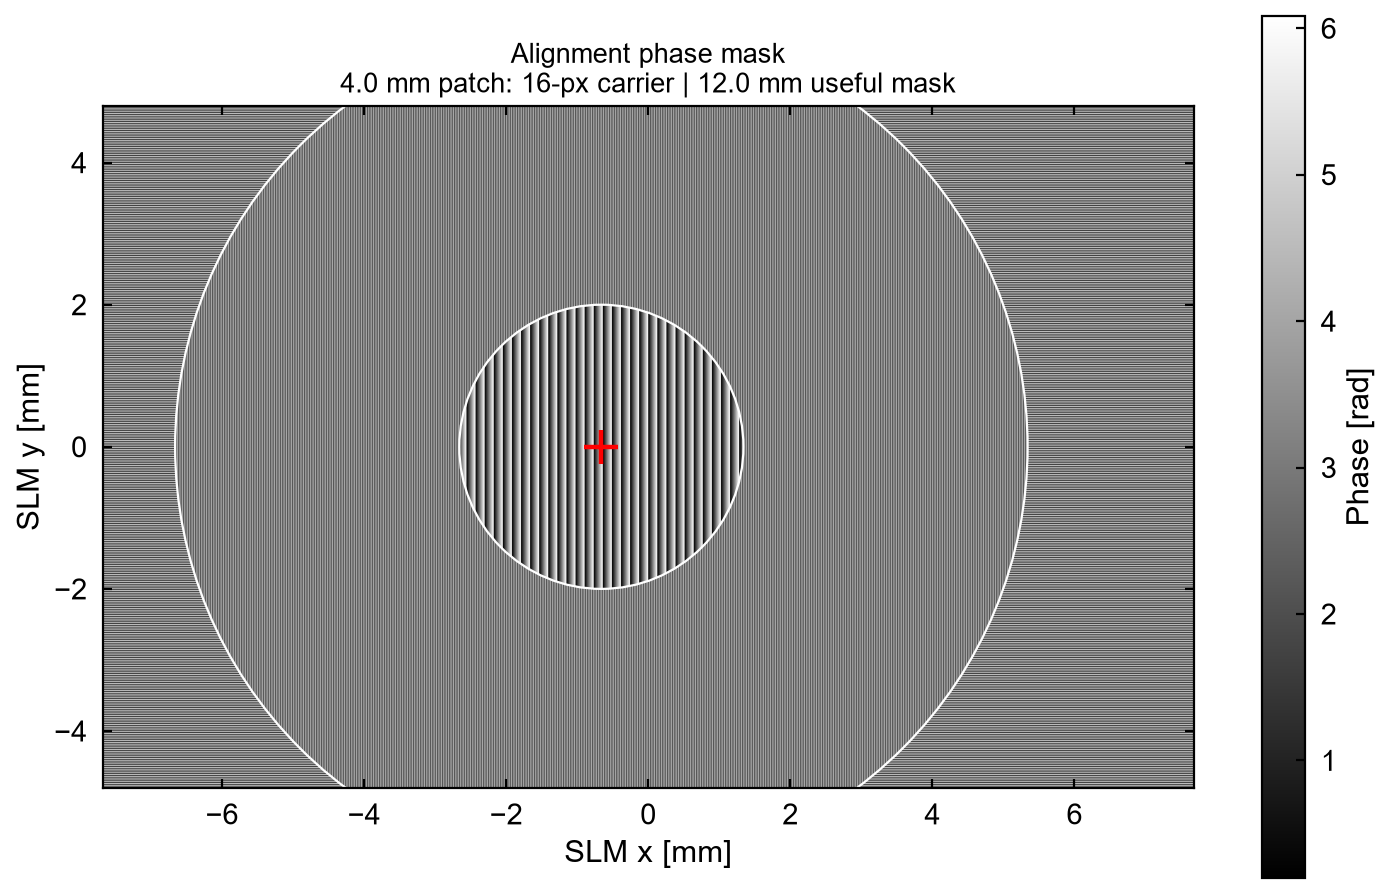

In [61]:
# ============================================================
# PLOT PHASE PATTERN
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 7))

im = plt.imshow(
    phase_alignment,
    origin="lower",
    cmap="gray",
    extent=[
        x_mm.min(),
        x_mm.max(),
        y_mm.min(),
        y_mm.max()
    ]
)

plt.colorbar(im, label="Phase [rad]")


# Inner alignment-patch boundary
inner_circle = plt.Circle(
    (X0_MM, Y0_MM),
    patch_radius_mm,
    fill=False,
    color="white",
    linewidth=1
)

plt.gca().add_patch(inner_circle)


# Outer useful-mask boundary
outer_circle = plt.Circle(
    (X0_MM, Y0_MM),
    mask_radius_mm,
    fill=False,
    color="white",
    linewidth=1
)

plt.gca().add_patch(outer_circle)


# Measured Gaussian centre
plt.plot(
    X0_MM,
    Y0_MM,
    "r+",
    markersize=15,
    markeredgewidth=2
)


plt.xlabel("SLM x [mm]")
plt.ylabel("SLM y [mm]")

plt.title(
    "Alignment phase mask\n"
    f"{PATCH_DIAMETER_MM:.1f} mm patch: "
    f"{CARRIER_PERIOD_PX}-px carrier | "
    f"{MASK_DIAMETER_MM:.1f} mm useful mask"
)

plt.xlim(-7.68, 7.68)
plt.ylim(-4.8, 4.8)

plt.show()

In [62]:
print("Writing three-region alignment mask to SLM...")

slm.set_phase(
    phase_alignment,
    phase_correct=True,
    settle=True,
)

print("Done.")

Writing three-region alignment mask to SLM...
Done.


data at the fourier plane:

patch used is 2 mm

-3.0 is 0.894 mW
-2.75 is 0.981 mW
-2.5 is 1.067
-2.25 1.149
-2.0 is 1.233
-1.75 is 1.317
-1.50 is 1.384
-1.25 is 1.441
-1.00 is 1.485
-0.75 is 1.522
-0.5 is 1.556
-0.25 is 1.565
-0.00 is 1.556
0.25 is 1.535
0.5 is 1.501
0.75 is 1.412
1.0 is 1.291
1.25 is 1.09
1.50 is 0.8867
1.75 is 0.667
2.0 is 0.469
2.25 is 0.297
2.5 is 0.138
2.75 is 46 uW
3 is 19 uW

-3.5 is 1.90
-3.25 is 1.95 
-3.0 is 2.05
-2.75 is 2.255
-2.5 is 2.55
-2.25 is 2.87
-2.0 is 3.12
-1.75 is 3.28
-1.5 is 3.36
-1.25 is 3.41
-1.0 is 3.456
-0.75 is 3.478
-0.5 is 3.45
-0.25 is 3.37
-0.00 is 3.14
0.25 is 2.7
0.5 is 2.29
0.75 is 1.934
1.0 is 1.75


more finer scan in x direction:

-1.5 gives 8.6
-1.25 gives 9.12
-1.2 gives 9.21
-1.1 gives 9.24
-1.15 gives 9.25
-1.0 gives 9.22
-0.9 gives 9.12
-0.8 gives 8.95
-0.75 gives 8.81
-0.70 gives 8.89
-0.5 gives 7.99

NOW THE Y AXIS AT X=1.08 mm

-2.0 is 3.95
-1.75 is 4.54
-1.5 is 5.2
-1.25 is 5.91
-1.0 is 6.66
-0.75 is 7.39
-0.5 is 8.10
-0.25 is 8.89
-0.15 is 9.14
-0.1 is 9.22
0.0 is 9.28
0.1 is 0.26
0.15 is 9.22
0.2 is 9.17
0.25 is 9.11
0.5 is 8.56
0.75 is 7.70
1.0 is 6.95
1.25 is 6.20
1.5 is 5.47
1.75 is 4.73
2.0 is 4.11

===== SLM GAUSSIAN BEAM PROFILE =====
X center: -0.6625 ± 0.0179 mm
Y center: -0.4479 ± 0.0416 mm

X 1/e² radius: 4.9845 mm
Y 1/e² radius: 4.3690 mm

X 1/e² diameter: 9.9689 mm
Y 1/e² diameter: 8.7380 mm

X R²: 0.99872
Y R²: 0.99571


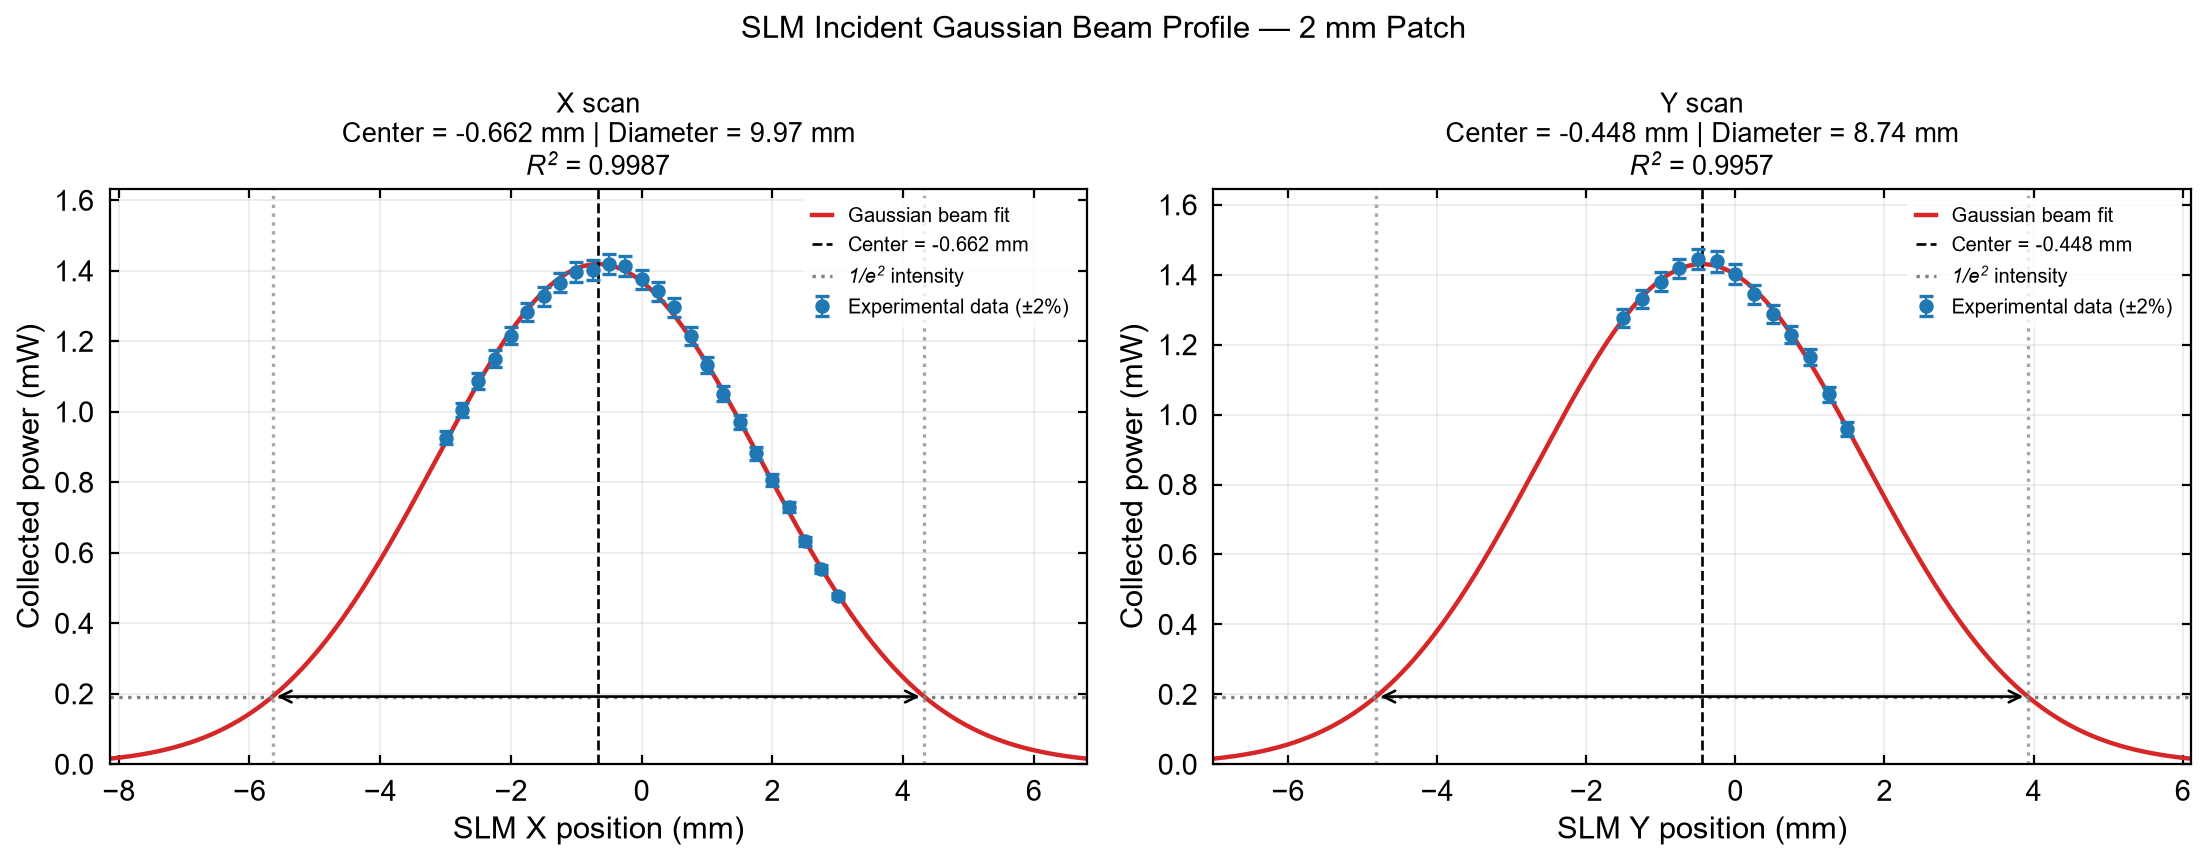

In [6]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ============================================================
# 1. EXPERIMENTAL DATA
# ============================================================

# Horizontal scan (Y = 0 mm)
x = np.arange(-3.0, 3.01, 0.25)

Px = np.array([
    0.927, 1.006, 1.087, 1.151, 1.216,
    1.284, 1.328, 1.366, 1.396, 1.403,
    1.419, 1.413, 1.376, 1.342, 1.296,
    1.215, 1.132, 1.051, 0.971, 0.882,
    0.806, 0.729, 0.633, 0.554, 0.477
])

# Vertical scan (X = -0.655 mm)
y = np.arange(-1.5, 1.51, 0.25)

Py = np.array([
    1.276, 1.331, 1.380, 1.418, 1.444,
    1.438, 1.402, 1.344, 1.287, 1.229,
    1.164, 1.058, 0.959
])

# ============================================================
# 2. MEASUREMENT UNCERTAINTIES (±2%)
# ============================================================

Px_err = 0.02 * Px
Py_err = 0.02 * Py

# ============================================================
# 3. GAUSSIAN BEAM MODEL
# ============================================================

def gaussian_beam(r, P0, r0, w):
    """
    P0 : Peak collected power (mW)
    r0 : Gaussian center (mm)
    w  : 1/e^2 intensity radius (mm)
    """
    return P0 * np.exp(-2 * ((r - r0) / w)**2)

# ============================================================
# 4. WEIGHTED GAUSSIAN FITTING
# ============================================================

fit_x, cov_x = curve_fit(
    gaussian_beam, x, Px,
    p0=[Px.max(), -0.65, 4.8],
    sigma=Px_err,
    absolute_sigma=True
)

fit_y, cov_y = curve_fit(
    gaussian_beam, y, Py,
    p0=[Py.max(), -0.45, 4.8],
    sigma=Py_err,
    absolute_sigma=True
)

P0x, x0, wx = fit_x
P0y, y0, wy = fit_y

err_x = np.sqrt(np.diag(cov_x))
err_y = np.sqrt(np.diag(cov_y))

# ============================================================
# 5. GOODNESS OF FIT
# ============================================================

def r_squared(data, prediction):
    return 1 - (
        np.sum((data - prediction)**2) /
        np.sum((data - data.mean())**2)
    )

R2x = r_squared(Px, gaussian_beam(x, *fit_x))
R2y = r_squared(Py, gaussian_beam(y, *fit_y))

print("===== SLM GAUSSIAN BEAM PROFILE =====")

print(f"X center: {x0:.4f} ± {err_x[1]:.4f} mm")
print(f"Y center: {y0:.4f} ± {err_y[1]:.4f} mm")

print(f"\nX 1/e² radius: {wx:.4f} mm")
print(f"Y 1/e² radius: {wy:.4f} mm")

print(f"\nX 1/e² diameter: {2*wx:.4f} mm")
print(f"Y 1/e² diameter: {2*wy:.4f} mm")

print(f"\nX R²: {R2x:.5f}")
print(f"Y R²: {R2y:.5f}")

# ============================================================
# 6. PLOT FULL GAUSSIANS
# ============================================================

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5.5)
)

datasets = [
    (x, Px, Px_err, fit_x, R2x, "X", axes[0]),
    (y, Py, Py_err, fit_y, R2y, "Y", axes[1])
]

for r, power, error, fit, r2, direction, ax in datasets:

    P0, center, w = fit
    diameter = 2 * w

    # FULL GAUSSIAN: extend to ±1.5 beam radii
    rr = np.linspace(
        center - 1.5*w,
        center + 1.5*w,
        1000
    )

    # Experimental measurements with errors
    ax.errorbar(
        r, power,
        yerr=error,
        fmt='o',
        color='tab:blue',
        markersize=5,
        capsize=3,
        elinewidth=1,
        label="Experimental data (±2%)",
        zorder=3
    )

    # Full fitted Gaussian curve
    ax.plot(
        rr,
        gaussian_beam(rr, *fit),
        color='tab:red',
        linewidth=2,
        label="Gaussian beam fit"
    )

    # Gaussian center
    ax.axvline(
        center,
        color='black',
        linestyle='--',
        linewidth=1.2,
        label=f"Center = {center:.3f} mm"
    )

    # 1/e² intensity level
    ax.axhline(
        P0 * np.exp(-2),
        color='gray',
        linestyle=':',
        label=r"$1/e^2$ intensity"
    )

    # Positions corresponding to ±w
    ax.axvline(
        center - w,
        color='gray',
        linestyle=':',
        alpha=0.7
    )

    ax.axvline(
        center + w,
        color='gray',
        linestyle=':',
        alpha=0.7
    )

    # Beam diameter annotation
    ax.annotate(
        "",
        xy=(center-w, P0*np.exp(-2)),
        xytext=(center+w, P0*np.exp(-2)),
        arrowprops=dict(
            arrowstyle="<->",
            color="black",
            lw=1.2
        )
    )

    ax.set_title(
        f"{direction} scan\n"
        f"Center = {center:.3f} mm | "
        f"Diameter = {diameter:.2f} mm\n"
        f"$R^2$ = {r2:.4f}"
    )

    ax.set_xlabel(f"SLM {direction} position (mm)")
    ax.set_ylabel("Collected power (mW)")

    ax.set_xlim(rr.min(), rr.max())
    ax.set_ylim(0, P0*1.15)

    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle(
    "SLM Incident Gaussian Beam Profile — 2 mm Patch",
    fontsize=14
)

plt.tight_layout()

# Save for DokuWiki
plt.savefig(
    "SLM_Gaussian_Profile_Full_With_Errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Existing wavefront correction found.
Wavefront correction: ON

===== ARRAY PARAMETERS =====
SLM shape: (1200, 1920)
FFT shape: (2048, 2048)
Array: 15 x 15
Number of spots: 225
Array center (knm): (1152.0, 1024.0)
Pitch (knm): 12.8


  0%|          | 0/30 [00:00<?, ?it/s]


Optimization complete.
Hologram shape: (1200, 1920)

===== SLM DISPLAY =====
15 x 15 array displayed.
Phase correction: True


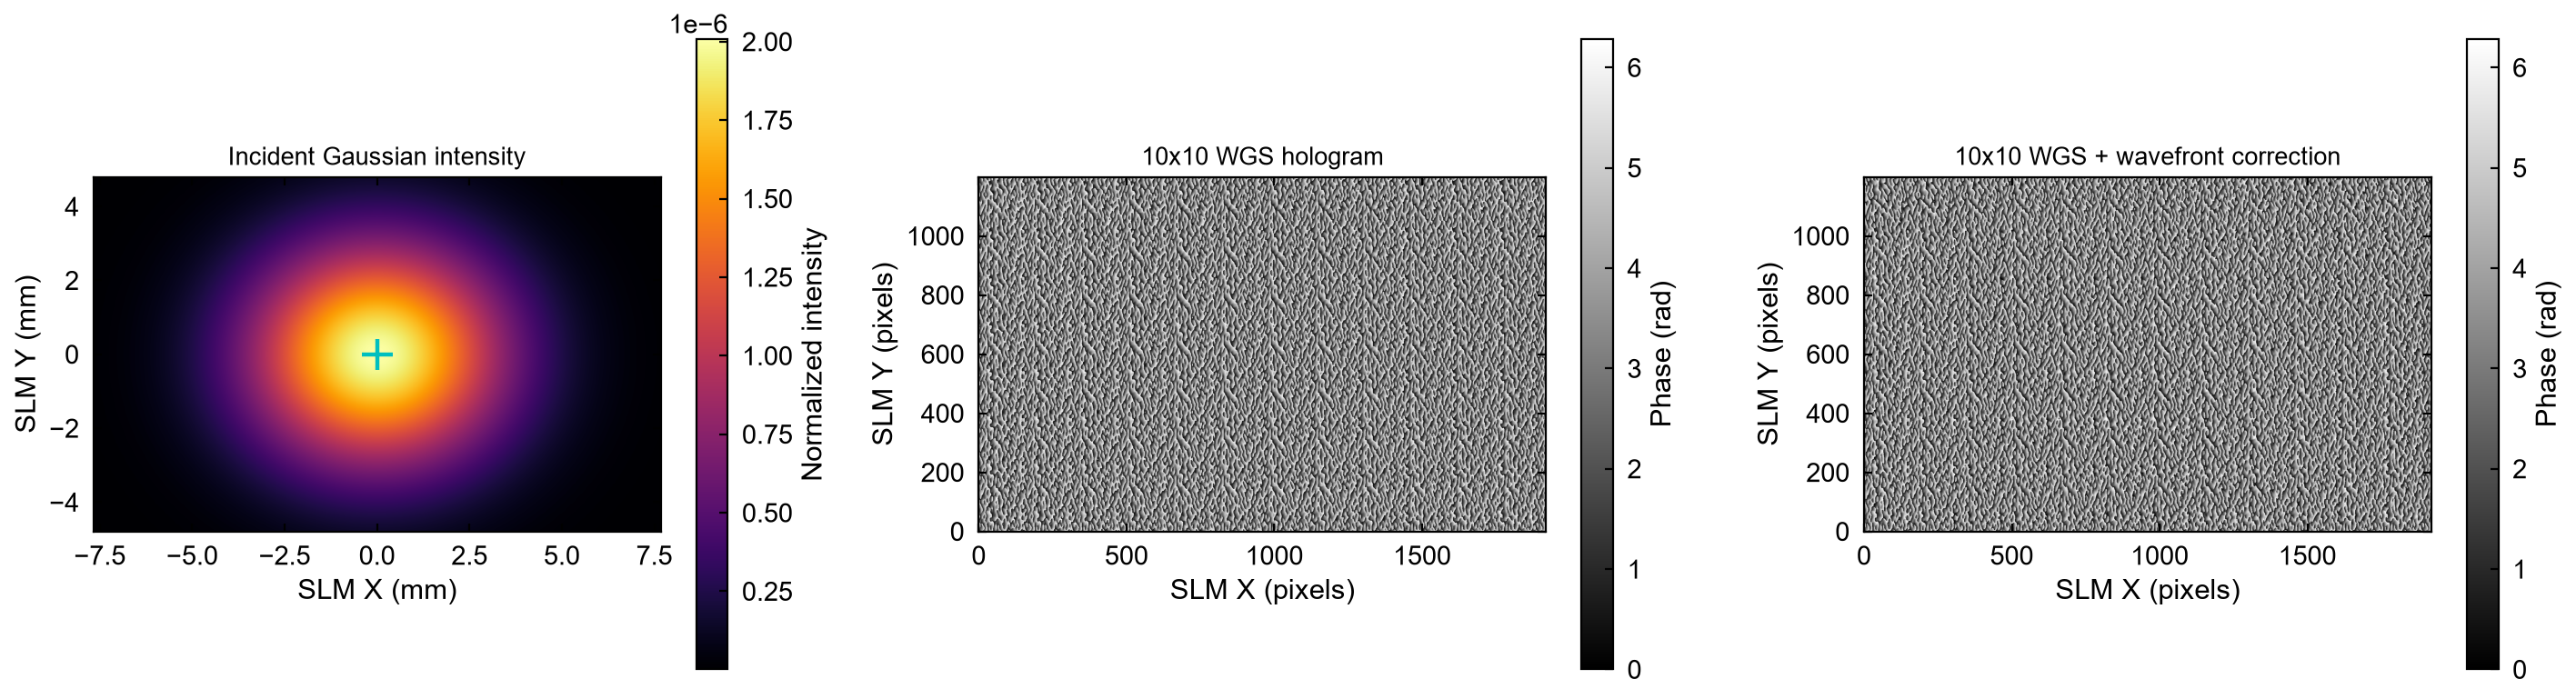

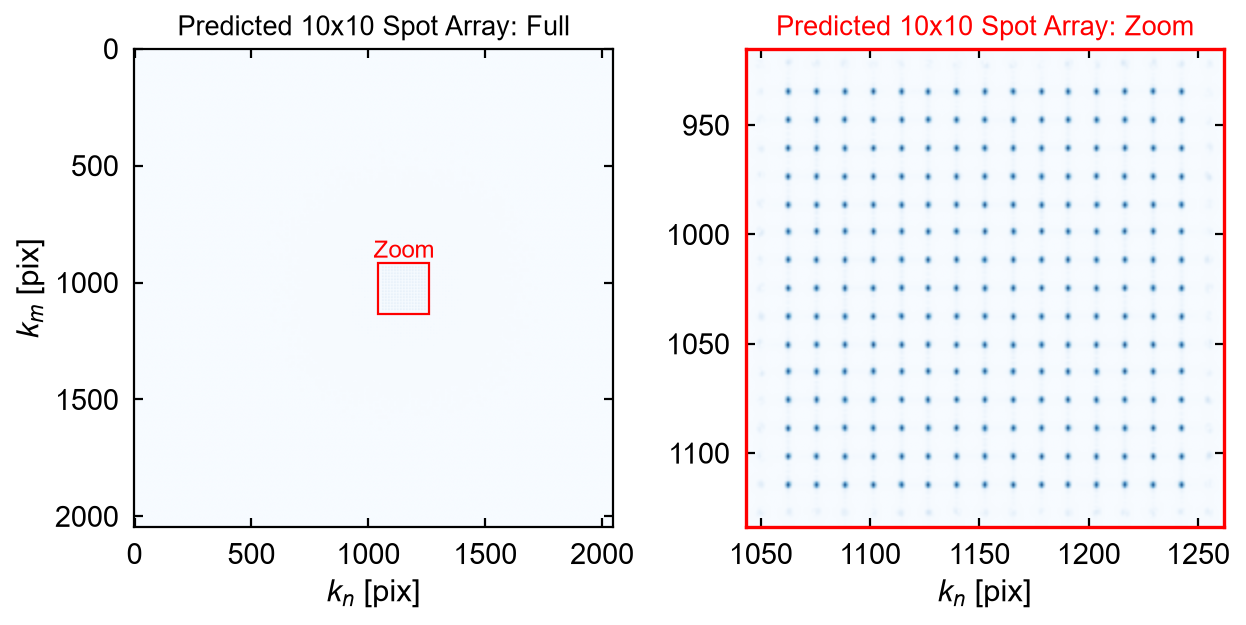

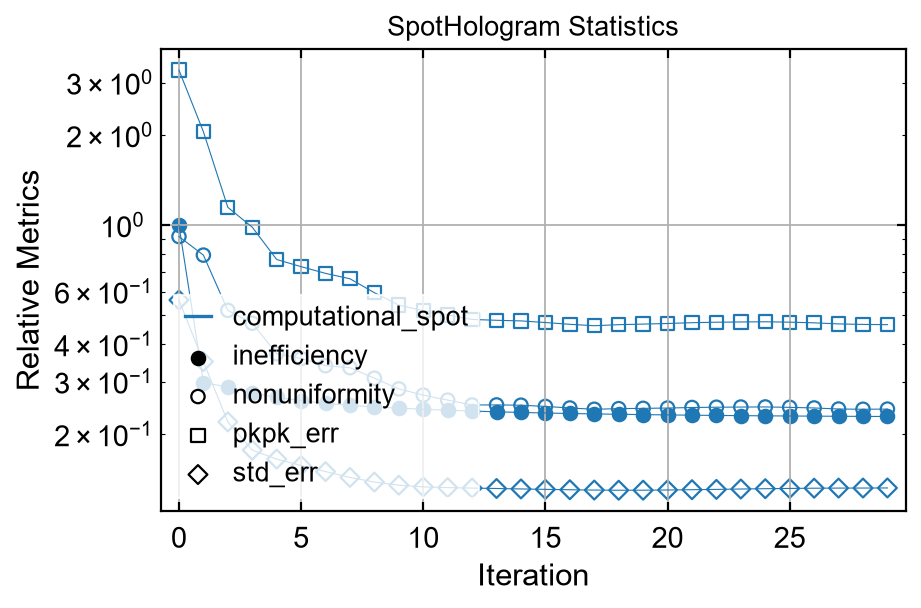


===== EXPECTED CAMERA ARRAY =====
X pitch: 177.96 um (96.20 camera px)
Y pitch: 177.96 um (96.20 camera px)
X array span: 2.491 mm
Y array span: 2.491 mm
Number of spots: 225
Wavefront correction: True


In [12]:

import numpy as np
import matplotlib.pyplot as plt
from slmsuite.holography.algorithms import SpotHologram


# ============================================================
# 1. PARAMETERS — CHANGE THESE
# ============================================================

ny, nx = slm.shape

FFT_SHAPE = (2048, 2048)

# Array dimensions
ARRAY_NX = 15
ARRAY_NY = 15

# Spot spacing in computational Fourier pixels
PITCH_KNM = 16*4.0/5

# Existing +16-pixel carrier in X
CARRIER_PERIOD_PX = 16

# Measured Gaussian illumination center
X0_MM = -0.00
Y0_MM = -0.00

# SLM pixel pitch
PIXEL_MM = 0.008

# Gaussian 1/e² intensity radii
WX_MM = 4.9
WY_MM = 4.25

# WGS optimization
WGS_ITERATIONS = 30

# Enable existing wavefront correction
PHASE_CORRECT = True

# Optical parameters
WAVELENGTH_MM = 759.3e-6
F1_MM = 300.0

CAMERA_PIXEL_UM = 1.85


# ============================================================
# 2. HELPER FUNCTION
# ============================================================

def to_numpy(array):
    """
    Convert NumPy or CuPy arrays to NumPy.
    """
    if hasattr(array, "get"):
        return array.get()
    return np.asarray(array)


# ============================================================
# 3. CHECK EXISTING WAVEFRONT CORRECTION
# ============================================================

if PHASE_CORRECT:

    if slm.source.get("phase") is None:
        raise RuntimeError(
            "No wavefront correction loaded in "
            "slm.source['phase']!"
        )

    correction = to_numpy(
        slm.source["phase"]
    )

    if correction.shape != slm.shape:
        raise ValueError(
            f"Correction shape {correction.shape} "
            f"does not match SLM shape {slm.shape}"
        )

    if not np.all(np.isfinite(correction)):
        raise ValueError(
            "Wavefront correction contains NaN or inf."
        )

    print("Existing wavefront correction found.")
    print("Wavefront correction: ON")

else:

    correction = np.zeros(slm.shape)

    print("Wavefront correction: OFF")


# ============================================================
# 4. SLM COORDINATES
# ============================================================

yy, xx = np.indices((ny, nx))

x_mm = (xx - (nx - 1) / 2) * PIXEL_MM
y_mm = (yy - (ny - 1) / 2) * PIXEL_MM


# ============================================================
# 5. INPUT GAUSSIAN AMPLITUDE
# ============================================================

# Electric-field amplitude:
#
# E(x,y) = E0 * exp(
#     -(x-x0)^2/wx^2
#     -(y-y0)^2/wy^2
# )
#
# Intensity = |E|^2

amp = np.exp(
    -((x_mm - X0_MM) / WX_MM)**2
    -((y_mm - Y0_MM) / WY_MM)**2
).astype(np.float32)

# Normalize peak amplitude
amp /= amp.max()


# ============================================================
# 6. ARRAY CENTER IN FOURIER SPACE
# ============================================================

fy, fx = FFT_SHAPE

# Zero order:
# (fx/2, fy/2)

# +16-pixel carrier:
center_x = fx / 2 + fx / CARRIER_PERIOD_PX
center_y = fy / 2

array_center = (center_x, center_y)

print("\n===== ARRAY PARAMETERS =====")
print("SLM shape:", slm.shape)
print("FFT shape:", FFT_SHAPE)
print(f"Array: {ARRAY_NX} x {ARRAY_NY}")
print("Number of spots:", ARRAY_NX * ARRAY_NY)
print("Array center (knm):", array_center)
print("Pitch (knm):", PITCH_KNM)


# ============================================================
# 7. GENERATE 10x10 HOLOGRAM
# ============================================================

holo = SpotHologram.make_rectangular_array(
    shape=FFT_SHAPE,
    array_shape=(ARRAY_NX, ARRAY_NY),
    array_pitch=(PITCH_KNM, PITCH_KNM),
    array_center=array_center,
    basis="knm",
    slm_shape=slm.shape,
    amp=amp,
    orientation_check=False
)


# ============================================================
# 8. COMPUTATIONAL WGS OPTIMIZATION
# ============================================================

holo.optimize(
    method="WGS-Leonardo",
    maxiter=WGS_ITERATIONS,
    feedback="computational_spot",
    stat_groups=["computational_spot"]
)


# ============================================================
# 9. EXTRACT OPTIMIZED PHASE
# ============================================================

phase_10x10 = to_numpy(
    holo.get_phase()
).copy()

# Wrap for visualization
phase_10x10 = np.mod(
    phase_10x10,
    2 * np.pi
)

print("\nOptimization complete.")
print("Hologram shape:", phase_10x10.shape)


# ============================================================
# 10. DISPLAY ON SLM
# ============================================================

# IMPORTANT:
# Do NOT manually add the correction here.
# slmsuite adds slm.source["phase"] automatically
# when phase_correct=True.

slm.set_phase(
    phase_10x10.copy(),
    phase_correct=PHASE_CORRECT,
    settle=True
)

print("\n===== SLM DISPLAY =====")
print(f"{ARRAY_NX} x {ARRAY_NY} array displayed.")
print("Phase correction:", PHASE_CORRECT)


# ============================================================
# 11. CORRECTED PHASE FOR VISUALIZATION
# ============================================================

# This is only for plotting.
# It is NOT sent to the SLM again.

phase_corrected = np.mod(
    phase_10x10 + correction,
    2 * np.pi
)


# ============================================================
# 12. PLOT INPUT AMPLITUDE AND PHASE PATTERNS
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

# ------------------------------------------------------------
# Input Gaussian intensity
# ------------------------------------------------------------

im0 = axes[0].imshow(
    amp**2,
    origin="lower",
    cmap="inferno",
    extent=[
        x_mm.min(), x_mm.max(),
        y_mm.min(), y_mm.max()
    ]
)

axes[0].plot(
    X0_MM,
    Y0_MM,
    "c+",
    markersize=15,
    markeredgewidth=2
)

axes[0].set_title(
    "Incident Gaussian intensity"
)

axes[0].set_xlabel("SLM X (mm)")
axes[0].set_ylabel("SLM Y (mm)")

plt.colorbar(
    im0,
    ax=axes[0],
    label="Normalized intensity"
)


# ------------------------------------------------------------
# WGS phase without correction
# ------------------------------------------------------------

im1 = axes[1].imshow(
    phase_10x10,
    origin="lower",
    cmap="gray",
    vmin=0,
    vmax=2*np.pi
)

axes[1].set_title(
    "10x10 WGS hologram"
)

axes[1].set_xlabel("SLM X (pixels)")
axes[1].set_ylabel("SLM Y (pixels)")

plt.colorbar(
    im1,
    ax=axes[1],
    label="Phase (rad)"
)


# ------------------------------------------------------------
# WGS phase including wavefront correction
# ------------------------------------------------------------

im2 = axes[2].imshow(
    phase_corrected,
    origin="lower",
    cmap="gray",
    vmin=0,
    vmax=2*np.pi
)

axes[2].set_title(
    "10x10 WGS + wavefront correction"
)

axes[2].set_xlabel("SLM X (pixels)")
axes[2].set_ylabel("SLM Y (pixels)")

plt.colorbar(
    im2,
    ax=axes[2],
    label="Phase (rad)"
)

plt.tight_layout()
plt.show()


# ============================================================
# 13. PLOT PREDICTED FAR FIELD
# ============================================================

holo.plot_farfield(
    title="Predicted 10x10 Spot Array"
)

plt.show()


# ============================================================
# 14. PLOT WGS CONVERGENCE
# ============================================================

holo.plot_stats()

plt.show()


# ============================================================
# 15. EXPECTED SPOT SPACING AT WGS CAMERA
# ============================================================

pitch_x_mm = (
    F1_MM
    * WAVELENGTH_MM
    * PITCH_KNM
    / (fx * PIXEL_MM)
)

pitch_y_mm = (
    F1_MM
    * WAVELENGTH_MM
    * PITCH_KNM
    / (fy * PIXEL_MM)
)

pitch_x_um = pitch_x_mm * 1000
pitch_y_um = pitch_y_mm * 1000

pitch_x_camera_px = pitch_x_um / CAMERA_PIXEL_UM
pitch_y_camera_px = pitch_y_um / CAMERA_PIXEL_UM

span_x_mm = (ARRAY_NX - 1) * pitch_x_mm
span_y_mm = (ARRAY_NY - 1) * pitch_y_mm

print("\n===== EXPECTED CAMERA ARRAY =====")

print(
    f"X pitch: {pitch_x_um:.2f} um "
    f"({pitch_x_camera_px:.2f} camera px)"
)

print(
    f"Y pitch: {pitch_y_um:.2f} um "
    f"({pitch_y_camera_px:.2f} camera px)"
)

print(f"X array span: {span_x_mm:.3f} mm")
print(f"Y array span: {span_y_mm:.3f} mm")

print(
    f"Number of spots: "
    f"{ARRAY_NX * ARRAY_NY}"
)

print("Wavefront correction:", PHASE_CORRECT)


In [20]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from scipy.optimize import curve_fit

# ============================================================
# 1. PARAMETERS
# ============================================================

IMAGE_PATH = r"C:\Users\admin\Desktop\camera longitudinal scan\array_15.bmp"

NX = 15
NY = 15

CAMERA_PIXEL_UM = 1.85

# Previously measured array center (camera pixels)
CENTER_X = 2555.87
CENTER_Y = 2093.87

# Previously measured grid vectors
# These include camera rotation and pitch anisotropy
GRID_A = np.array([122.143, 0.946])
GRID_B = np.array([-0.888, 120.305])

# Search for actual spot near predicted position
SEARCH_RADIUS = 12

# Gaussian fitting window: 51 x 51 pixels
FIT_RADIUS = 25

# Power integration radius
POWER_RADIUS = 50

# Background annulus
BG_INNER = 51
BG_OUTER = 57

# Optical parameters for ideal PSF
WAVELENGTH_MM = 759.3e-6
FOCAL_LENGTH_MM = 300.0

SLM_WIDTH_MM = 15.36
SLM_HEIGHT_MM = 9.60

WX_MM = 4.9
WY_MM = 4.25

X0_MM = -0.66
Y0_MM = -0.45


# ============================================================
# 2. LOAD IMAGE
# ============================================================

image = np.array(
    Image.open(IMAGE_PATH).convert("L"),
    dtype=np.float64
)

height, width = image.shape

print("Image shape:", image.shape)
print("Maximum pixel value:", image.max())
print("Total saturated pixels:", np.sum(image >= 255))


# ============================================================
# 3. ROTATED 2D GAUSSIAN MODEL
# ============================================================

def gaussian_2d(coords, A, x0, y0, wx, wy, theta, B):
    """
    A     : Peak intensity above background
    x0,y0 : Spot center
    wx,wy : 1/e^2 intensity radii in pixels
    theta : Rotation angle in radians
    B     : Constant background
    """

    x, y = coords

    dx = x - x0
    dy = y - y0

    u = dx*np.cos(theta) + dy*np.sin(theta)
    v = -dx*np.sin(theta) + dy*np.cos(theta)

    intensity = B + A*np.exp(
        -2*((u/wx)**2 + (v/wy)**2)
    )

    return intensity.ravel()


# ============================================================
# 4. IDEAL DIFFRACTION-LIMITED PSF
# ============================================================

def ideal_normalized_peak(radius=50, subpixels=5):
    """
    Calculate the ideal peak / integrated power ratio.

    Reference pupil:
    elliptical Gaussian illumination truncated by the
    full rectangular SLM aperture.

    Includes approximate integration over each camera pixel.
    """

    camera_pitch = CAMERA_PIXEL_UM * 1e-3

    # SLM coordinates
    sx = np.linspace(
        -SLM_WIDTH_MM/2,
        SLM_WIDTH_MM/2,
        1921
    )

    sy = np.linspace(
        -SLM_HEIGHT_MM/2,
        SLM_HEIGHT_MM/2,
        1201
    )

    # Incident electric-field amplitudes
    Ex = np.exp(-((sx-X0_MM)/WX_MM)**2)
    Ey = np.exp(-((sy-Y0_MM)/WY_MM)**2)

    # Camera sampling positions
    pixels = np.arange(-radius, radius+1)

    offsets = (
        (np.arange(subpixels)+0.5)/subpixels - 0.5
    )

    q = (
        pixels[:, None] + offsets[None, :]
    ) * camera_pitch

    q = q.ravel()

    # Fraunhofer diffraction from the separable pupil
    Fx = np.exp(
        -2j*np.pi*np.outer(q, sx) /
        (WAVELENGTH_MM*FOCAL_LENGTH_MM)
    ) @ Ex

    Fy = np.exp(
        -2j*np.pi*np.outer(q, sy) /
        (WAVELENGTH_MM*FOCAL_LENGTH_MM)
    ) @ Ey

    Ix = np.mean(
        np.abs(Fx.reshape(-1, subpixels))**2,
        axis=1
    )

    Iy = np.mean(
        np.abs(Fy.reshape(-1, subpixels))**2,
        axis=1
    )

    ideal_psf = np.outer(Iy, Ix)

    yy, xx = np.meshgrid(
        pixels, pixels, indexing="ij"
    )

    aperture = xx**2 + yy**2 <= radius**2

    ideal_peak = ideal_psf[radius, radius]
    ideal_power = ideal_psf[aperture].sum()

    return ideal_peak / ideal_power


IDEAL_PEAK_RATIO = ideal_normalized_peak(
    radius=POWER_RADIUS
)

print(
    "Ideal normalized peak:",
    IDEAL_PEAK_RATIO
)


# ============================================================
# 5. FIT ONE SPOT
# ============================================================

def fit_single_spot(image, x_pred, y_pred):

    H, W = image.shape

    xp = int(round(x_pred))
    yp = int(round(y_pred))

    # --------------------------------------------------------
    # Locate the actual maximum near predicted coordinates
    # --------------------------------------------------------

    s = SEARCH_RADIUS

    search = image[
        yp-s:yp+s+1,
        xp-s:xp+s+1
    ]

    if search.shape != (2*s+1, 2*s+1):
        raise ValueError("Search window outside image")

    iy, ix = np.unravel_index(
        np.argmax(search),
        search.shape
    )

    xc = xp-s+ix
    yc = yp-s+iy

    # --------------------------------------------------------
    # Extract local fitting ROI
    # --------------------------------------------------------

    r = FIT_RADIUS

    roi = image[
        yc-r:yc+r+1,
        xc-r:xc+r+1
    ]

    if roi.shape != (2*r+1, 2*r+1):
        raise ValueError("Fitting ROI outside image")

    yy, xx = np.indices(roi.shape)

    xx = xx-r
    yy = yy-r

    rr = np.sqrt(xx**2 + yy**2)

    background_guess = np.median(
        roi[rr > 20]
    )

    peak_guess = max(
        roi.max()-background_guess,
        1.0
    )

    # Initial Gaussian parameters
    p0 = [
        peak_guess,
        0.0,
        0.0,
        10.5,
        11.0,
        0.0,
        background_guess
    ]

    bounds_lower = [
        0, -8, -8,
        2, 2, -np.pi, -np.inf
    ]

    bounds_upper = [
        np.inf, 8, 8,
        40, 40, np.pi, np.inf
    ]

    fit, cov = curve_fit(
        gaussian_2d,
        (xx, yy),
        roi.ravel(),
        p0=p0,
        bounds=(bounds_lower, bounds_upper),
        maxfev=5000
    )

    A, dx, dy, w1, w2, theta, B = fit

    x_fit = xc+dx
    y_fit = yc+dy

    # --------------------------------------------------------
    # Spot widths
    # --------------------------------------------------------

    # FWHM = sqrt(2 ln 2) * w
    # for I = I0 exp(-2 x^2 / w^2)

    w_minor = min(w1, w2)
    w_major = max(w1, w2)

    fwhm_minor = np.sqrt(2*np.log(2))*w_minor
    fwhm_major = np.sqrt(2*np.log(2))*w_major

    ellipticity = fwhm_major/fwhm_minor

    # Fitted Gaussian integrated power
    power_gaussian = (
        np.pi/2 * A * w1 * w2
    )

    # --------------------------------------------------------
    # Goodness of fit
    # --------------------------------------------------------

    fitted_roi = gaussian_2d(
        (xx, yy), *fit
    ).reshape(roi.shape)

    residual = roi-fitted_roi

    ss_res = np.sum(residual**2)
    ss_tot = np.sum((roi-roi.mean())**2)

    r_squared = 1-ss_res/ss_tot

    rmse = np.sqrt(np.mean(residual**2))

    # --------------------------------------------------------
    # Direct integrated power
    # --------------------------------------------------------

    q = BG_OUTER

    xi = int(round(x_fit))
    yi = int(round(y_fit))

    power_roi = image[
        yi-q:yi+q+1,
        xi-q:xi+q+1
    ]

    if power_roi.shape != (2*q+1, 2*q+1):
        raise ValueError("Power ROI outside image")

    YY, XX = np.indices(power_roi.shape)

    XX = XX+xi-q-x_fit
    YY = YY+yi-q-y_fit

    R = np.sqrt(XX**2 + YY**2)

    background_region = (
        (R >= BG_INNER) &
        (R <= BG_OUTER)
    )

    background = np.median(
        power_roi[background_region]
    )

    aperture = R <= POWER_RADIUS

    signal = power_roi-background

    power_direct = signal[aperture].sum()

    peak_measured = signal[aperture].max()

    saturated_pixels = np.sum(
        power_roi[aperture] >= 255
    )

    # --------------------------------------------------------
    # Strehl proxy
    # --------------------------------------------------------

    if power_direct > 0 and saturated_pixels == 0:

        strehl = (
            peak_measured/power_direct
        ) / IDEAL_PEAK_RATIO

    else:
        strehl = np.nan

    return {
        "x_px": x_fit,
        "y_px": y_fit,

        "peak_fit": A,
        "peak_measured": peak_measured,

        "power_direct": power_direct,
        "power_gaussian": power_gaussian,

        "fwhm_minor_px": fwhm_minor,
        "fwhm_major_px": fwhm_major,

        "fwhm_minor_um":
            fwhm_minor*CAMERA_PIXEL_UM,

        "fwhm_major_um":
            fwhm_major*CAMERA_PIXEL_UM,

        "fwhm_area":
            fwhm_minor*fwhm_major,

        "ellipticity": ellipticity,

        "background": background,

        "theta_deg": np.degrees(theta),

        "r_squared": r_squared,
        "rmse": rmse,

        "strehl_proxy": strehl,

        "saturated_pixels": saturated_pixels
    }


# ============================================================
# 6. ANALYZE ALL 225 SPOTS
# ============================================================

results = []

array_center = np.array([CENTER_X, CENTER_Y])

for row in range(NY):

    for col in range(NX):

        i = col-(NX-1)/2
        j = row-(NY-1)/2

        predicted = (
            array_center
            + i*GRID_A
            + j*GRID_B
        )

        result = fit_single_spot(
            image,
            predicted[0],
            predicted[1]
        )

        result["row"] = row
        result["col"] = col

        results.append(result)

    print(
        f"Completed row {row+1}/{NY}",
        flush=True
    )

df = pd.DataFrame(results)

print("\nSuccessfully fitted", len(df), "spots")

if df["saturated_pixels"].sum() > 0:
    print(
        "WARNING: Some intended spots are saturated!"
    )

# Save individual spot fits
df.to_csv(
    "SLM_15x15_individual_spot_fits.csv",
    index=False
)

df.head()


Image shape: (3036, 4024)
Maximum pixel value: 255.0
Total saturated pixels: 261
Ideal normalized peak: 0.006584948780795029
Completed row 1/15
Completed row 2/15
Completed row 3/15
Completed row 4/15
Completed row 5/15
Completed row 6/15
Completed row 7/15
Completed row 8/15
Completed row 9/15
Completed row 10/15
Completed row 11/15
Completed row 12/15
Completed row 13/15
Completed row 14/15
Completed row 15/15

Successfully fitted 225 spots


,x_px,y_px,peak_fit,peak_measured,power_direct,power_gaussian,fwhm_minor_px,fwhm_major_px,fwhm_minor_um,fwhm_major_um,fwhm_area,ellipticity,background,theta_deg,r_squared,rmse,strehl_proxy,saturated_pixels,row,col
0,1706.595271,1245.048513,128.325600,127.0,24885.0,23318.023065,12.264943,13.075204,22.690145,24.189126,160.366630,1.066063,0.0,39.776644,0.994738,1.617850,0.775021,0,0,0
1,1828.796138,1245.811288,155.939464,155.0,30237.0,28976.559062,12.505285,13.113926,23.134778,24.260764,163.993394,1.048671,0.0,-31.791375,0.995847,1.762139,0.778468,0,0,1
2,1951.229631,1246.881063,143.857101,144.0,26665.0,25614.482079,12.288439,12.787720,22.733613,23.657282,157.141124,1.040630,0.0,-12.357266,0.995669,1.630680,0.820103,0,0,2
3,2073.192920,1247.758298,132.870260,134.0,25724.0,24764.171877,12.535170,13.122040,23.190065,24.275775,164.487010,1.046818,0.0,18.291941,0.995768,1.517570,0.791068,0,0,3
4,2195.208446,1248.738240,142.615315,142.0,26688.0,25219.655855,12.209055,12.782816,22.586751,23.648209,156.066097,1.046995,0.0,-36.417082,0.995690,1.608091,0.808016,0,0,4


In [21]:

# ============================================================
# 7. STATISTICAL ANALYSIS
# ============================================================

def CV(values):
    values = np.asarray(values, dtype=float)
    return 100*np.nanstd(values)/np.nanmean(values)


power = df["power_direct"].to_numpy()
peak = df["peak_fit"].to_numpy()

minor = df["fwhm_minor_px"].to_numpy()
major = df["fwhm_major_px"].to_numpy()

ellipticity = df["ellipticity"].to_numpy()
strehl = df["strehl_proxy"].to_numpy()

# Normalize power and intensity
df["power_normalized"] = power/power.mean()
df["peak_normalized"] = peak/peak.mean()

print("="*60)
print("15 x 15 SLM ARRAY CHARACTERIZATION")
print("="*60)

print(f"\nNumber of spots: {len(df)}")

print("\n--- HOMOGENEITY ---")

print(f"Integrated power CV: {CV(power):.3f} %")

print(
    f"Gaussian power CV: "
    f"{CV(df['power_gaussian']):.3f} %"
)

print(f"Peak intensity CV: {CV(peak):.3f} %")

print(
    f"Weakest spot: "
    f"{100*power.min()/power.mean():.2f} %"
)

print(
    f"Strongest spot: "
    f"{100*power.max()/power.mean():.2f} %"
)

print("\n--- SPOT SIZE ---")

print(
    f"Minor FWHM: "
    f"{minor.mean():.3f} ± {minor.std():.3f} px"
)

print(
    f"Major FWHM: "
    f"{major.mean():.3f} ± {major.std():.3f} px"
)

print(
    f"Minor FWHM: "
    f"{minor.mean()*CAMERA_PIXEL_UM:.3f} ± "
    f"{minor.std()*CAMERA_PIXEL_UM:.3f} um"
)

print(
    f"Major FWHM: "
    f"{major.mean()*CAMERA_PIXEL_UM:.3f} ± "
    f"{major.std()*CAMERA_PIXEL_UM:.3f} um"
)

print(
    f"Ellipticity: "
    f"{ellipticity.mean():.4f} ± "
    f"{ellipticity.std():.4f}"
)

print("\n--- STREHL PROXY ---")

print(
    f"Mean Strehl: "
    f"{np.nanmean(strehl):.4f} ± "
    f"{np.nanstd(strehl):.4f}"
)

print(f"Minimum Strehl: {np.nanmin(strehl):.4f}")
print(f"Maximum Strehl: {np.nanmax(strehl):.4f}")

print(
    f"Fraction above 0.85: "
    f"{100*np.nanmean(strehl > 0.85):.1f} %"
)

print("\n--- FIT QUALITY ---")

print(f"Mean R²: {df['r_squared'].mean():.5f}")
print(f"Minimum R²: {df['r_squared'].min():.5f}")

print(
    f"Saturated intended pixels: "
    f"{df['saturated_pixels'].sum()}"
)


# ============================================================
# 8. AFFINE GRID FIT
# ============================================================

i = df["col"].to_numpy()-(NX-1)/2
j = df["row"].to_numpy()-(NY-1)/2

# r(i,j) = r0 + i*a + j*b
design_matrix = np.column_stack([
    np.ones(len(df)),
    i,
    j
])

positions = df[["x_px", "y_px"]].to_numpy()

coefficients, _, _, _ = np.linalg.lstsq(
    design_matrix,
    positions,
    rcond=None
)

r0 = coefficients[0]
a = coefficients[1]
b = coefficients[2]

positions_fitted = design_matrix @ coefficients

position_residuals = positions-positions_fitted

residual_distance = np.linalg.norm(
    position_residuals,
    axis=1
)

df["residual_x_px"] = position_residuals[:, 0]
df["residual_y_px"] = position_residuals[:, 1]
df["residual_position_px"] = residual_distance

pitch_x = np.linalg.norm(a)
pitch_y = np.linalg.norm(b)

rotation = np.degrees(
    np.arctan2(a[1], a[0])
)

orthogonality = np.degrees(
    np.arccos(
        np.clip(
            np.dot(a, b)/(pitch_x*pitch_y),
            -1, 1
        )
    )
)

rms_position_error = np.sqrt(
    np.mean(residual_distance**2)
)

print("\n--- ARRAY GEOMETRY ---")

print(
    f"Array center: "
    f"({r0[0]:.3f}, {r0[1]:.3f}) px"
)

print(
    f"Horizontal pitch: "
    f"{pitch_x:.3f} px = "
    f"{pitch_x*CAMERA_PIXEL_UM:.3f} um"
)

print(
    f"Vertical pitch: "
    f"{pitch_y:.3f} px = "
    f"{pitch_y*CAMERA_PIXEL_UM:.3f} um"
)

print(f"Pitch ratio X/Y: {pitch_x/pitch_y:.5f}")

print(f"Grid rotation: {rotation:.4f} deg")

print(
    f"Angle between grid axes: "
    f"{orthogonality:.4f} deg"
)

print(
    f"RMS position residual: "
    f"{rms_position_error:.4f} px"
)

print(
    f"Maximum position residual: "
    f"{residual_distance.max():.4f} px"
)

# Update saved CSV with all geometry information
df.to_csv(
    "SLM_15x15_individual_spot_fits.csv",
    index=False
)


15 x 15 SLM ARRAY CHARACTERIZATION

Number of spots: 225

--- HOMOGENEITY ---
Integrated power CV: 6.746 %
Gaussian power CV: 7.020 %
Peak intensity CV: 7.742 %
Weakest spot: 77.99 %
Strongest spot: 116.98 %

--- SPOT SIZE ---
Minor FWHM: 12.329 ± 0.241 px
Major FWHM: 13.015 ± 0.270 px
Minor FWHM: 22.808 ± 0.446 um
Major FWHM: 24.077 ± 0.500 um
Ellipticity: 1.0559 ± 0.0231

--- STREHL PROXY ---
Mean Strehl: 0.7973 ± 0.0285
Minimum Strehl: 0.6859
Maximum Strehl: 0.8581
Fraction above 0.85: 2.7 %

--- FIT QUALITY ---
Mean R²: 0.99575
Minimum R²: 0.99205
Saturated intended pixels: 0

--- ARRAY GEOMETRY ---
Array center: (2555.868, 2093.875) px
Horizontal pitch: 122.147 px = 225.972 um
Vertical pitch: 120.308 px = 222.570 um
Pitch ratio X/Y: 1.01529
Grid rotation: 0.4436 deg
Angle between grid axes: 89.9794 deg
RMS position residual: 0.3031 px
Maximum position residual: 0.7585 px


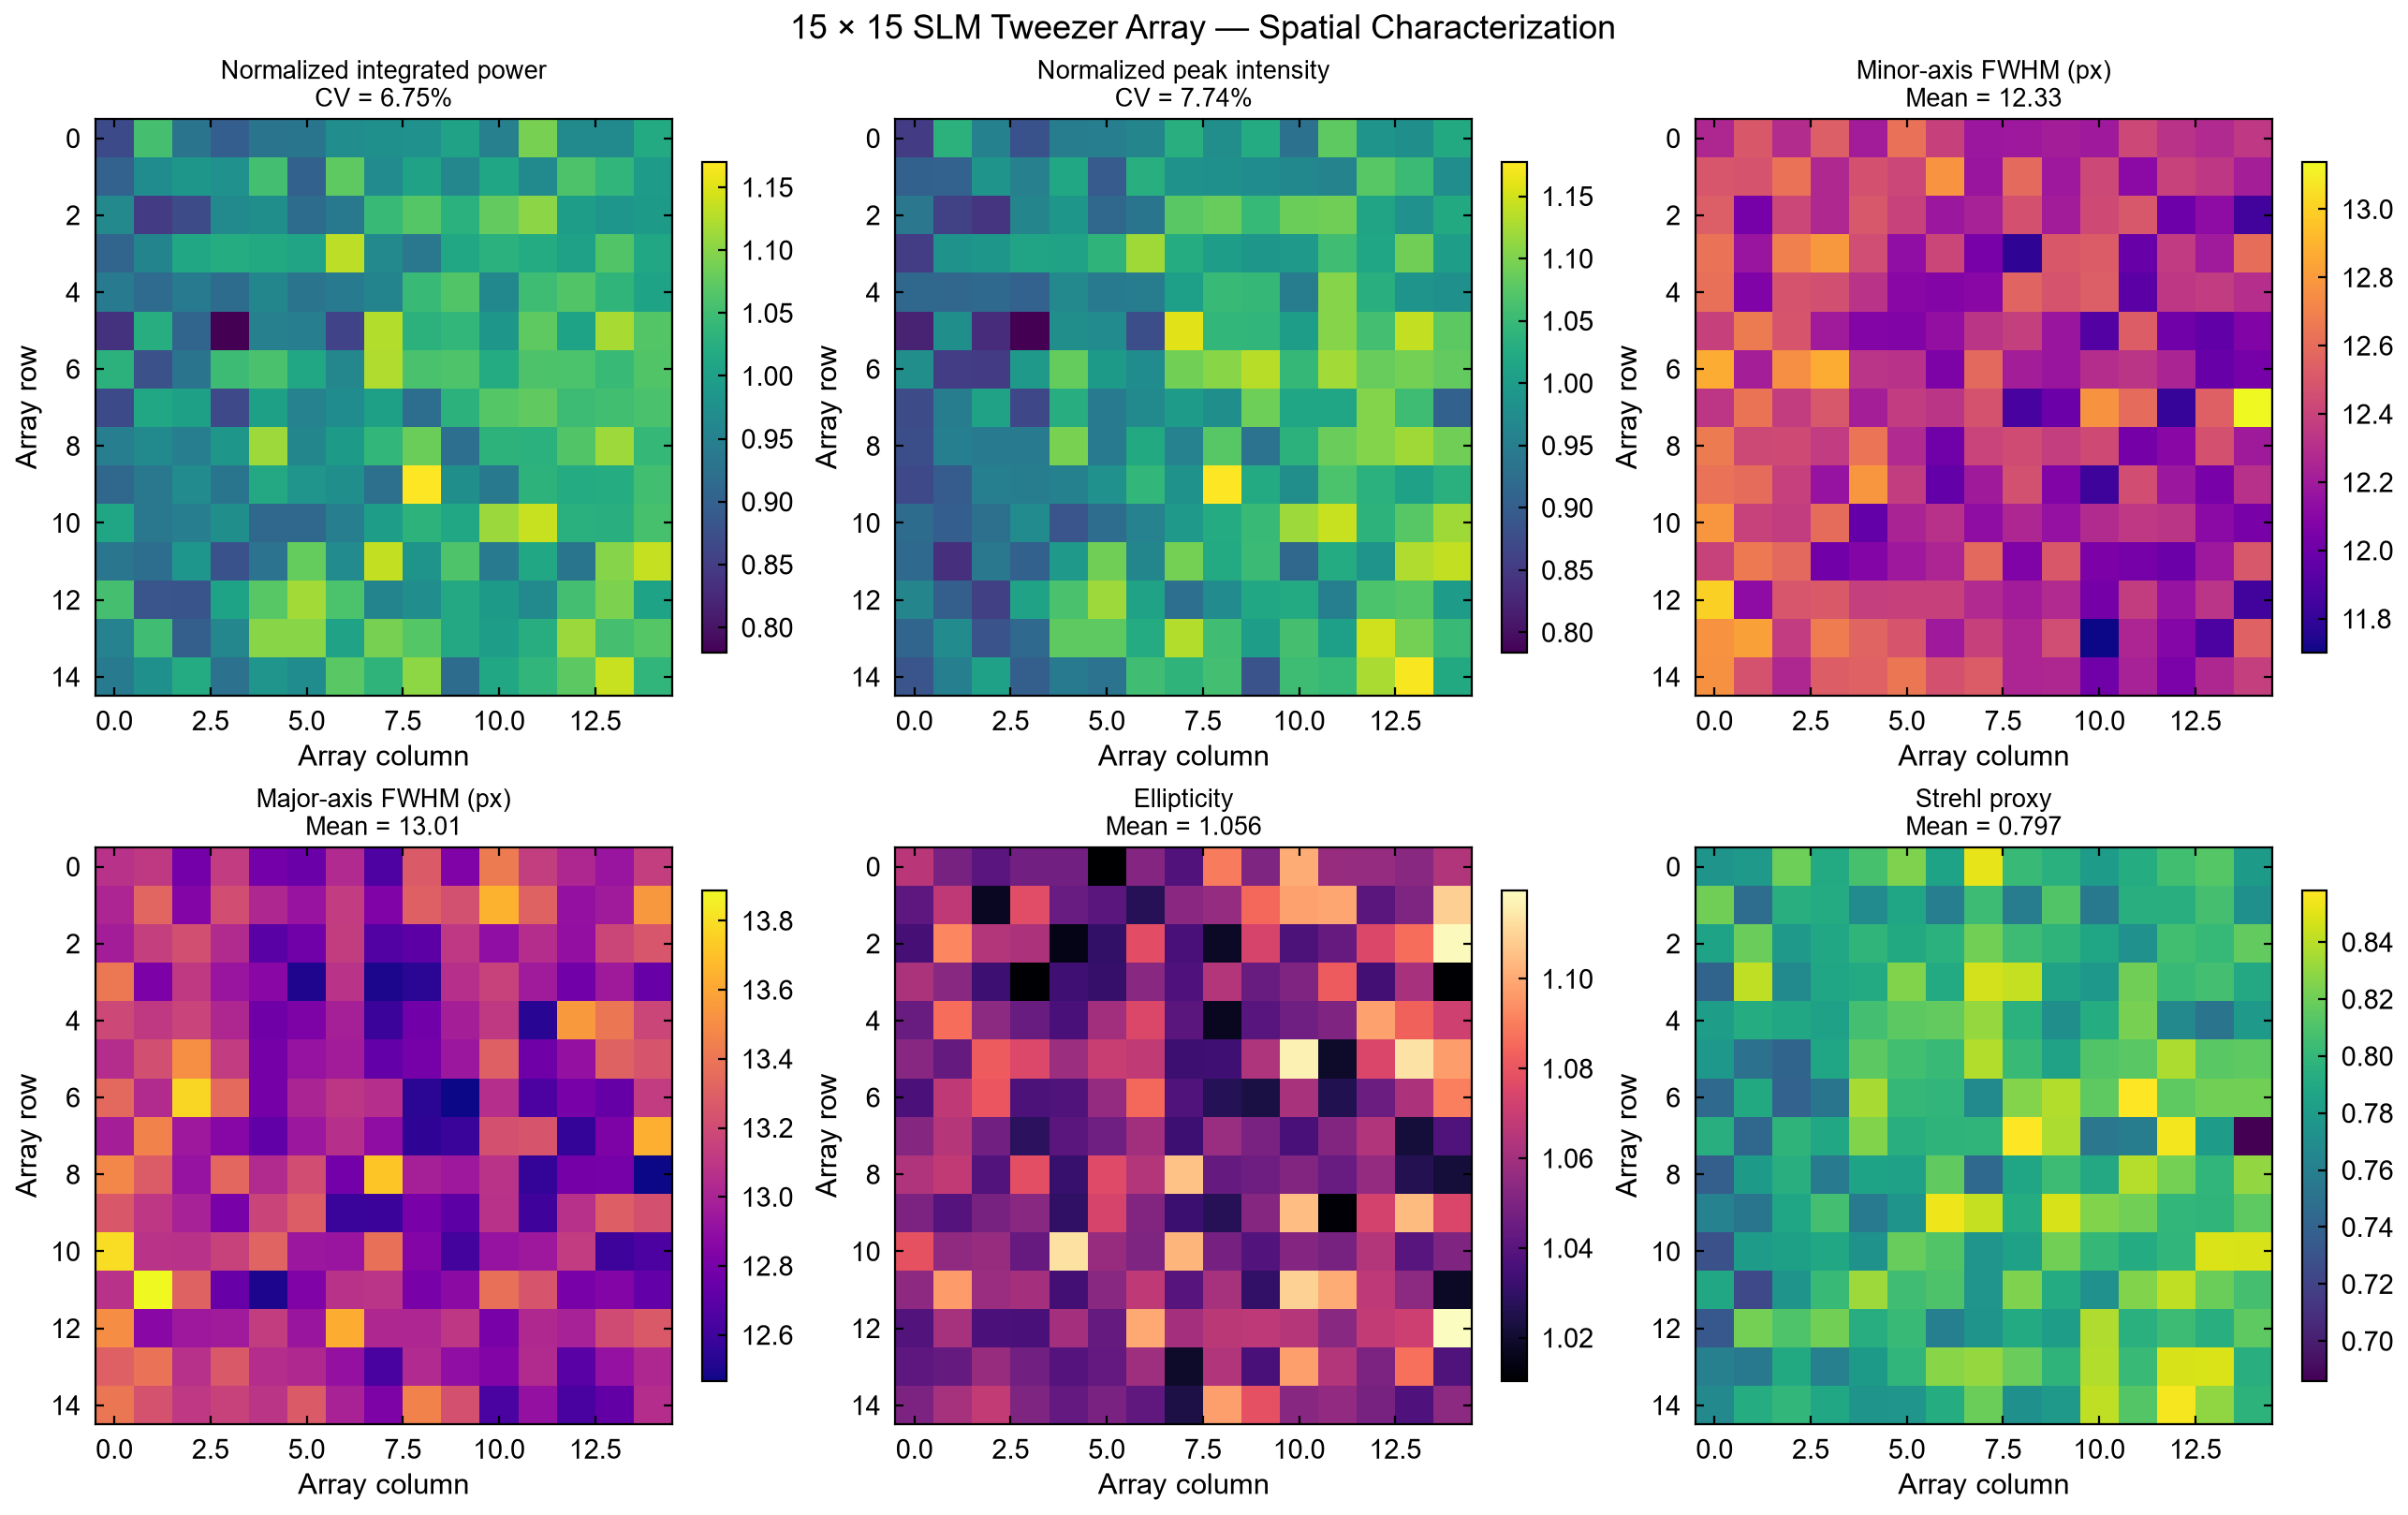

In [22]:

# ============================================================
# 9. SPATIAL HEATMAPS
# ============================================================

def make_map(column):
    return df.pivot(
        index="row",
        columns="col",
        values=column
    ).to_numpy()


fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    constrained_layout=True
)

maps = [
    (
        "power_normalized",
        f"Normalized integrated power\n"
        f"CV = {CV(power):.2f}%",
        "viridis"
    ),
    (
        "peak_normalized",
        f"Normalized peak intensity\n"
        f"CV = {CV(peak):.2f}%",
        "viridis"
    ),
    (
        "fwhm_minor_px",
        f"Minor-axis FWHM (px)\n"
        f"Mean = {minor.mean():.2f}",
        "plasma"
    ),
    (
        "fwhm_major_px",
        f"Major-axis FWHM (px)\n"
        f"Mean = {major.mean():.2f}",
        "plasma"
    ),
    (
        "ellipticity",
        f"Ellipticity\n"
        f"Mean = {ellipticity.mean():.3f}",
        "magma"
    ),
    (
        "strehl_proxy",
        f"Strehl proxy\n"
        f"Mean = {np.nanmean(strehl):.3f}",
        "viridis"
    )
]

for ax, (column, title, cmap) in zip(
    axes.ravel(), maps
):

    data_map = make_map(column)

    im = ax.imshow(
        data_map,
        cmap=cmap,
        origin="upper",
        interpolation="nearest"
    )

    ax.set_title(title, fontsize=12)

    ax.set_xlabel("Array column")
    ax.set_ylabel("Array row")

    plt.colorbar(
        im,
        ax=ax,
        shrink=0.85
    )

fig.suptitle(
    "15 × 15 SLM Tweezer Array — Spatial Characterization",
    fontsize=16
)

plt.savefig(
    "SLM_15x15_spatial_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


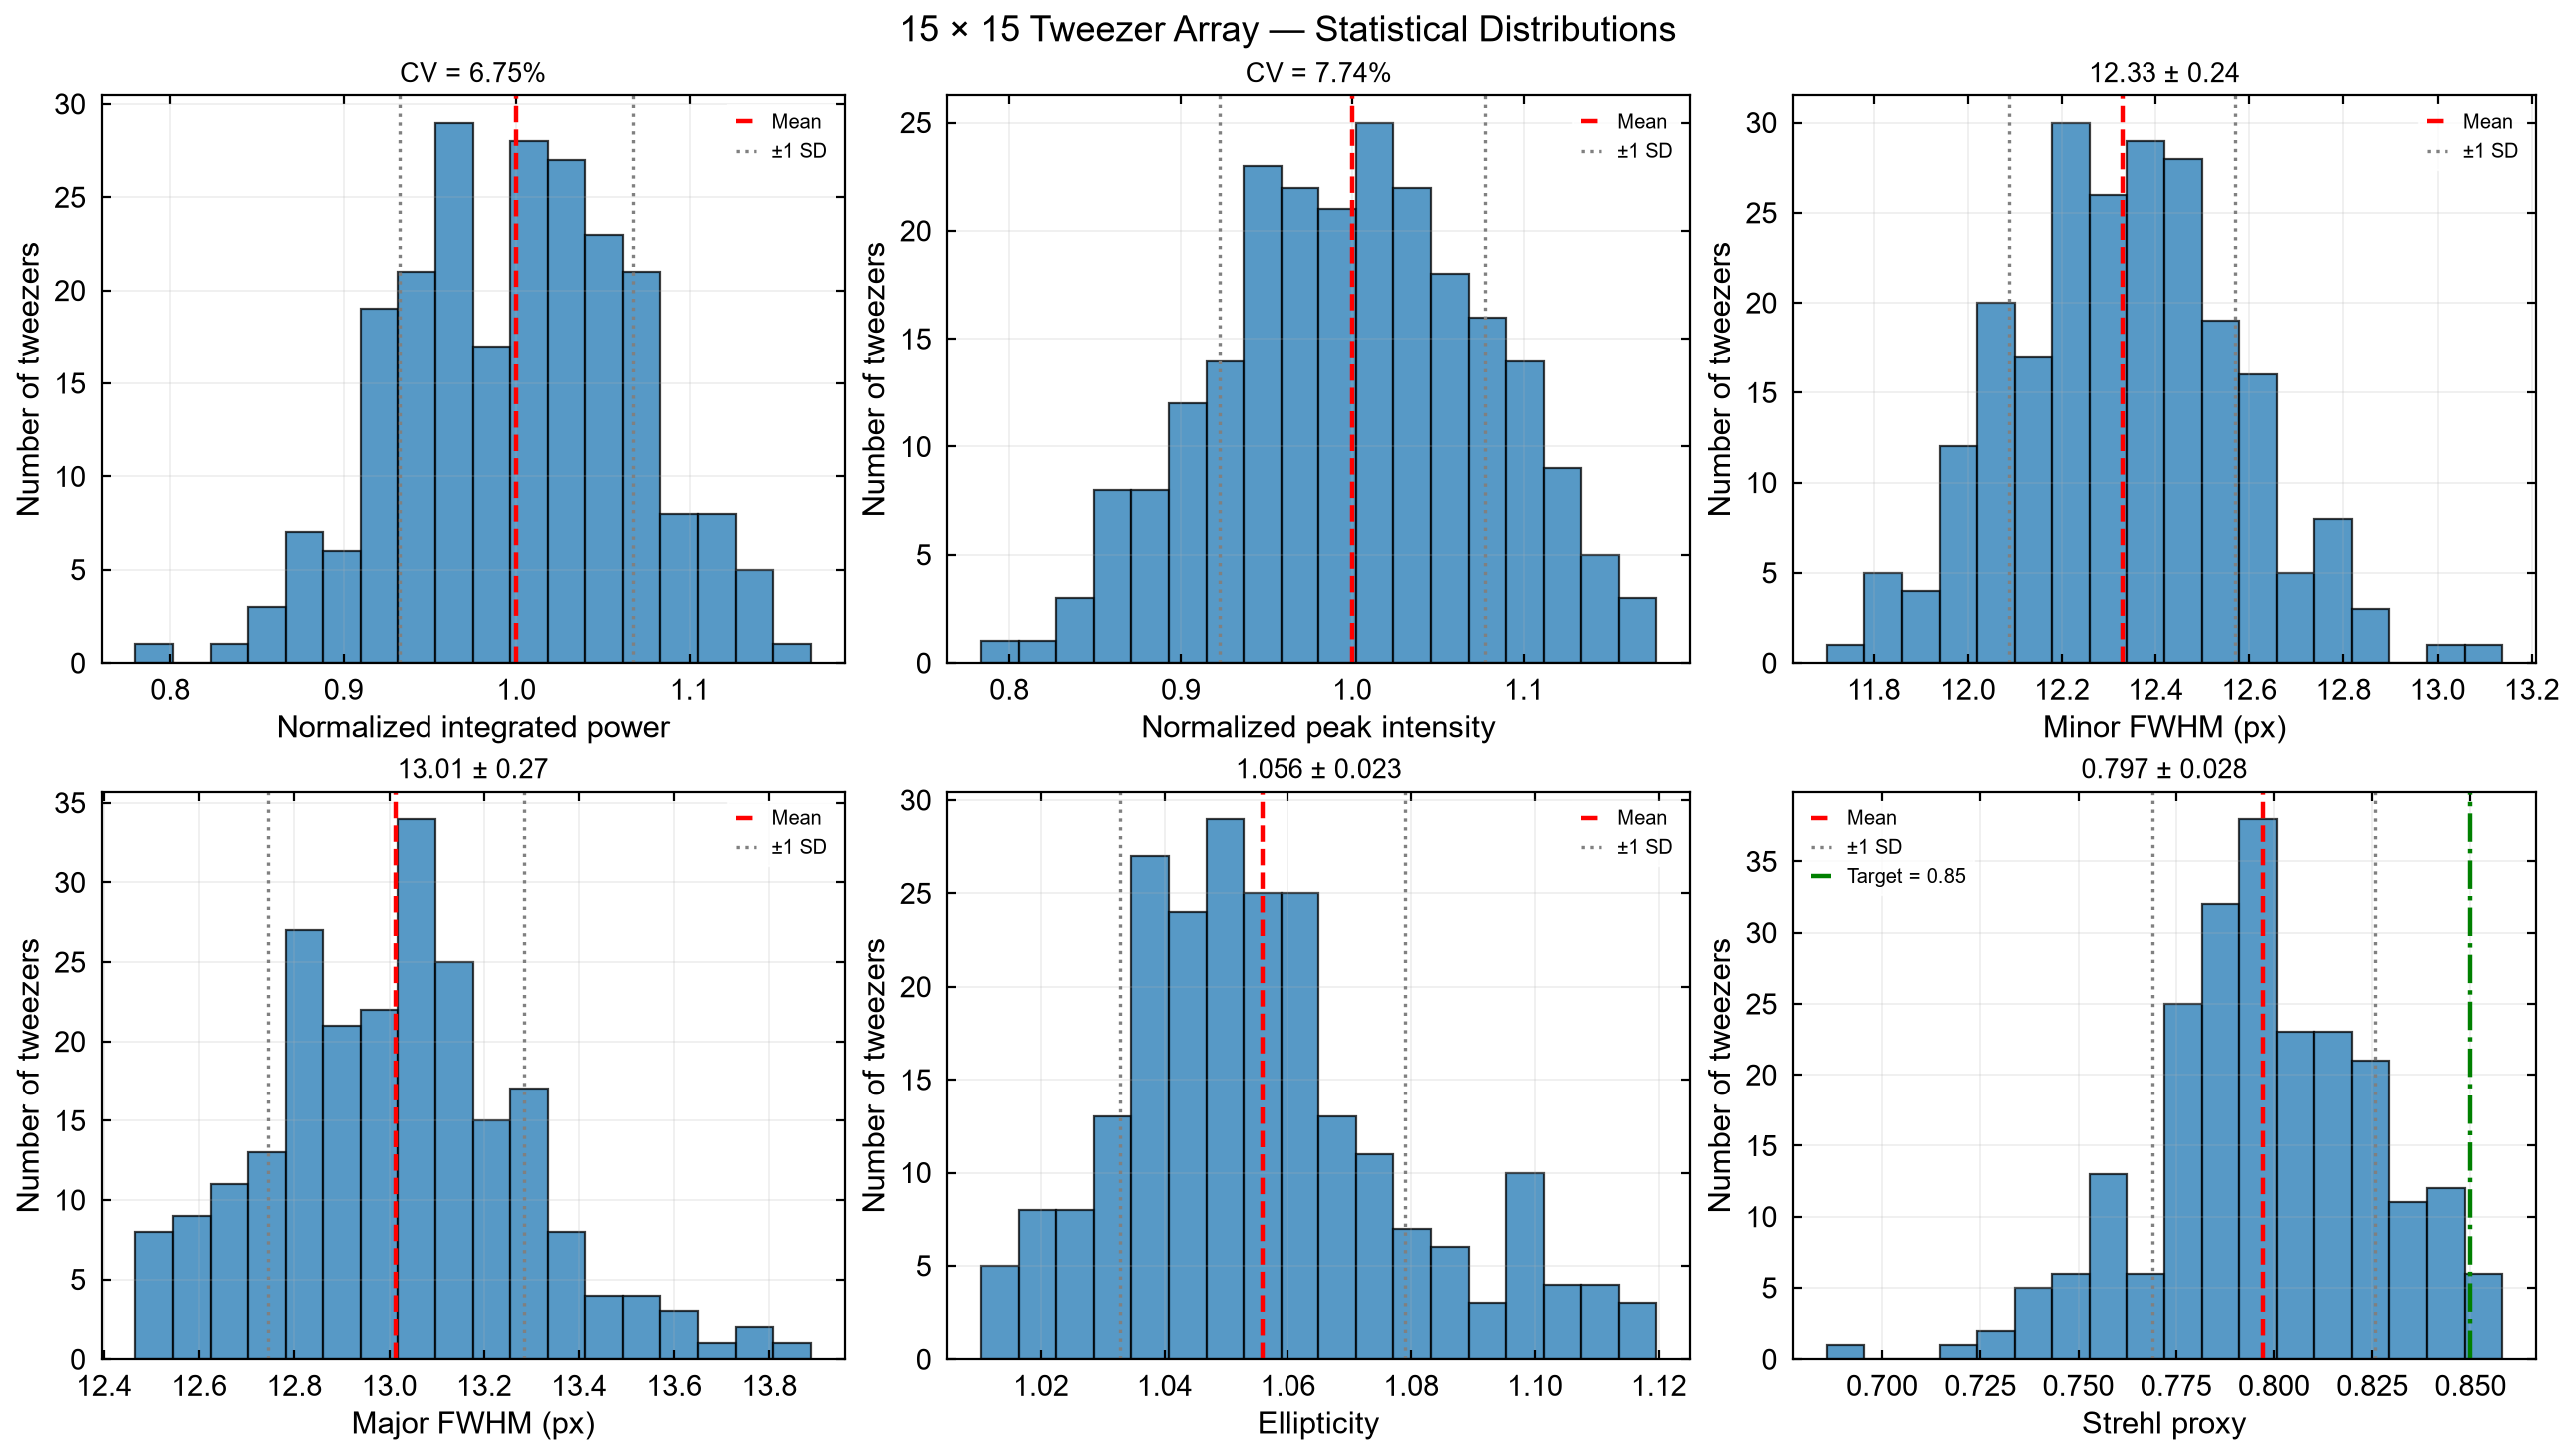

In [23]:

# ============================================================
# 10. HISTOGRAMS
# ============================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    constrained_layout=True
)

histograms = [
    (
        df["power_normalized"],
        "Normalized integrated power",
        f"CV = {CV(power):.2f}%"
    ),
    (
        df["peak_normalized"],
        "Normalized peak intensity",
        f"CV = {CV(peak):.2f}%"
    ),
    (
        minor,
        "Minor FWHM (px)",
        f"{minor.mean():.2f} ± {minor.std():.2f}"
    ),
    (
        major,
        "Major FWHM (px)",
        f"{major.mean():.2f} ± {major.std():.2f}"
    ),
    (
        ellipticity,
        "Ellipticity",
        f"{ellipticity.mean():.3f} ± "
        f"{ellipticity.std():.3f}"
    ),
    (
        strehl,
        "Strehl proxy",
        f"{np.nanmean(strehl):.3f} ± "
        f"{np.nanstd(strehl):.3f}"
    )
]

for ax, (values, xlabel, title) in zip(
    axes.ravel(), histograms
):

    values = np.asarray(values)
    values = values[np.isfinite(values)]

    ax.hist(
        values,
        bins=18,
        edgecolor="black",
        alpha=0.75
    )

    mean = values.mean()
    std = values.std()

    ax.axvline(
        mean,
        color="red",
        linestyle="--",
        linewidth=2,
        label="Mean"
    )

    ax.axvline(
        mean-std,
        color="gray",
        linestyle=":",
        linewidth=1.5
    )

    ax.axvline(
        mean+std,
        color="gray",
        linestyle=":",
        linewidth=1.5,
        label="±1 SD"
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number of tweezers")

    ax.set_title(title)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.2)

# Add desired Strehl threshold
axes[1, 2].axvline(
    0.85,
    color="green",
    linestyle="-.",
    linewidth=2,
    label="Target = 0.85"
)

axes[1, 2].legend(fontsize=9)

fig.suptitle(
    "15 × 15 Tweezer Array — Statistical Distributions",
    fontsize=16
)

plt.savefig(
    "SLM_15x15_histograms.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


X gradient, Minor FWHM: -0.3149 px across array
X gradient, Major FWHM: -0.1904 px across array
Y gradient, Minor FWHM: +0.0036 px across array
Y gradient, Major FWHM: +0.0216 px across array


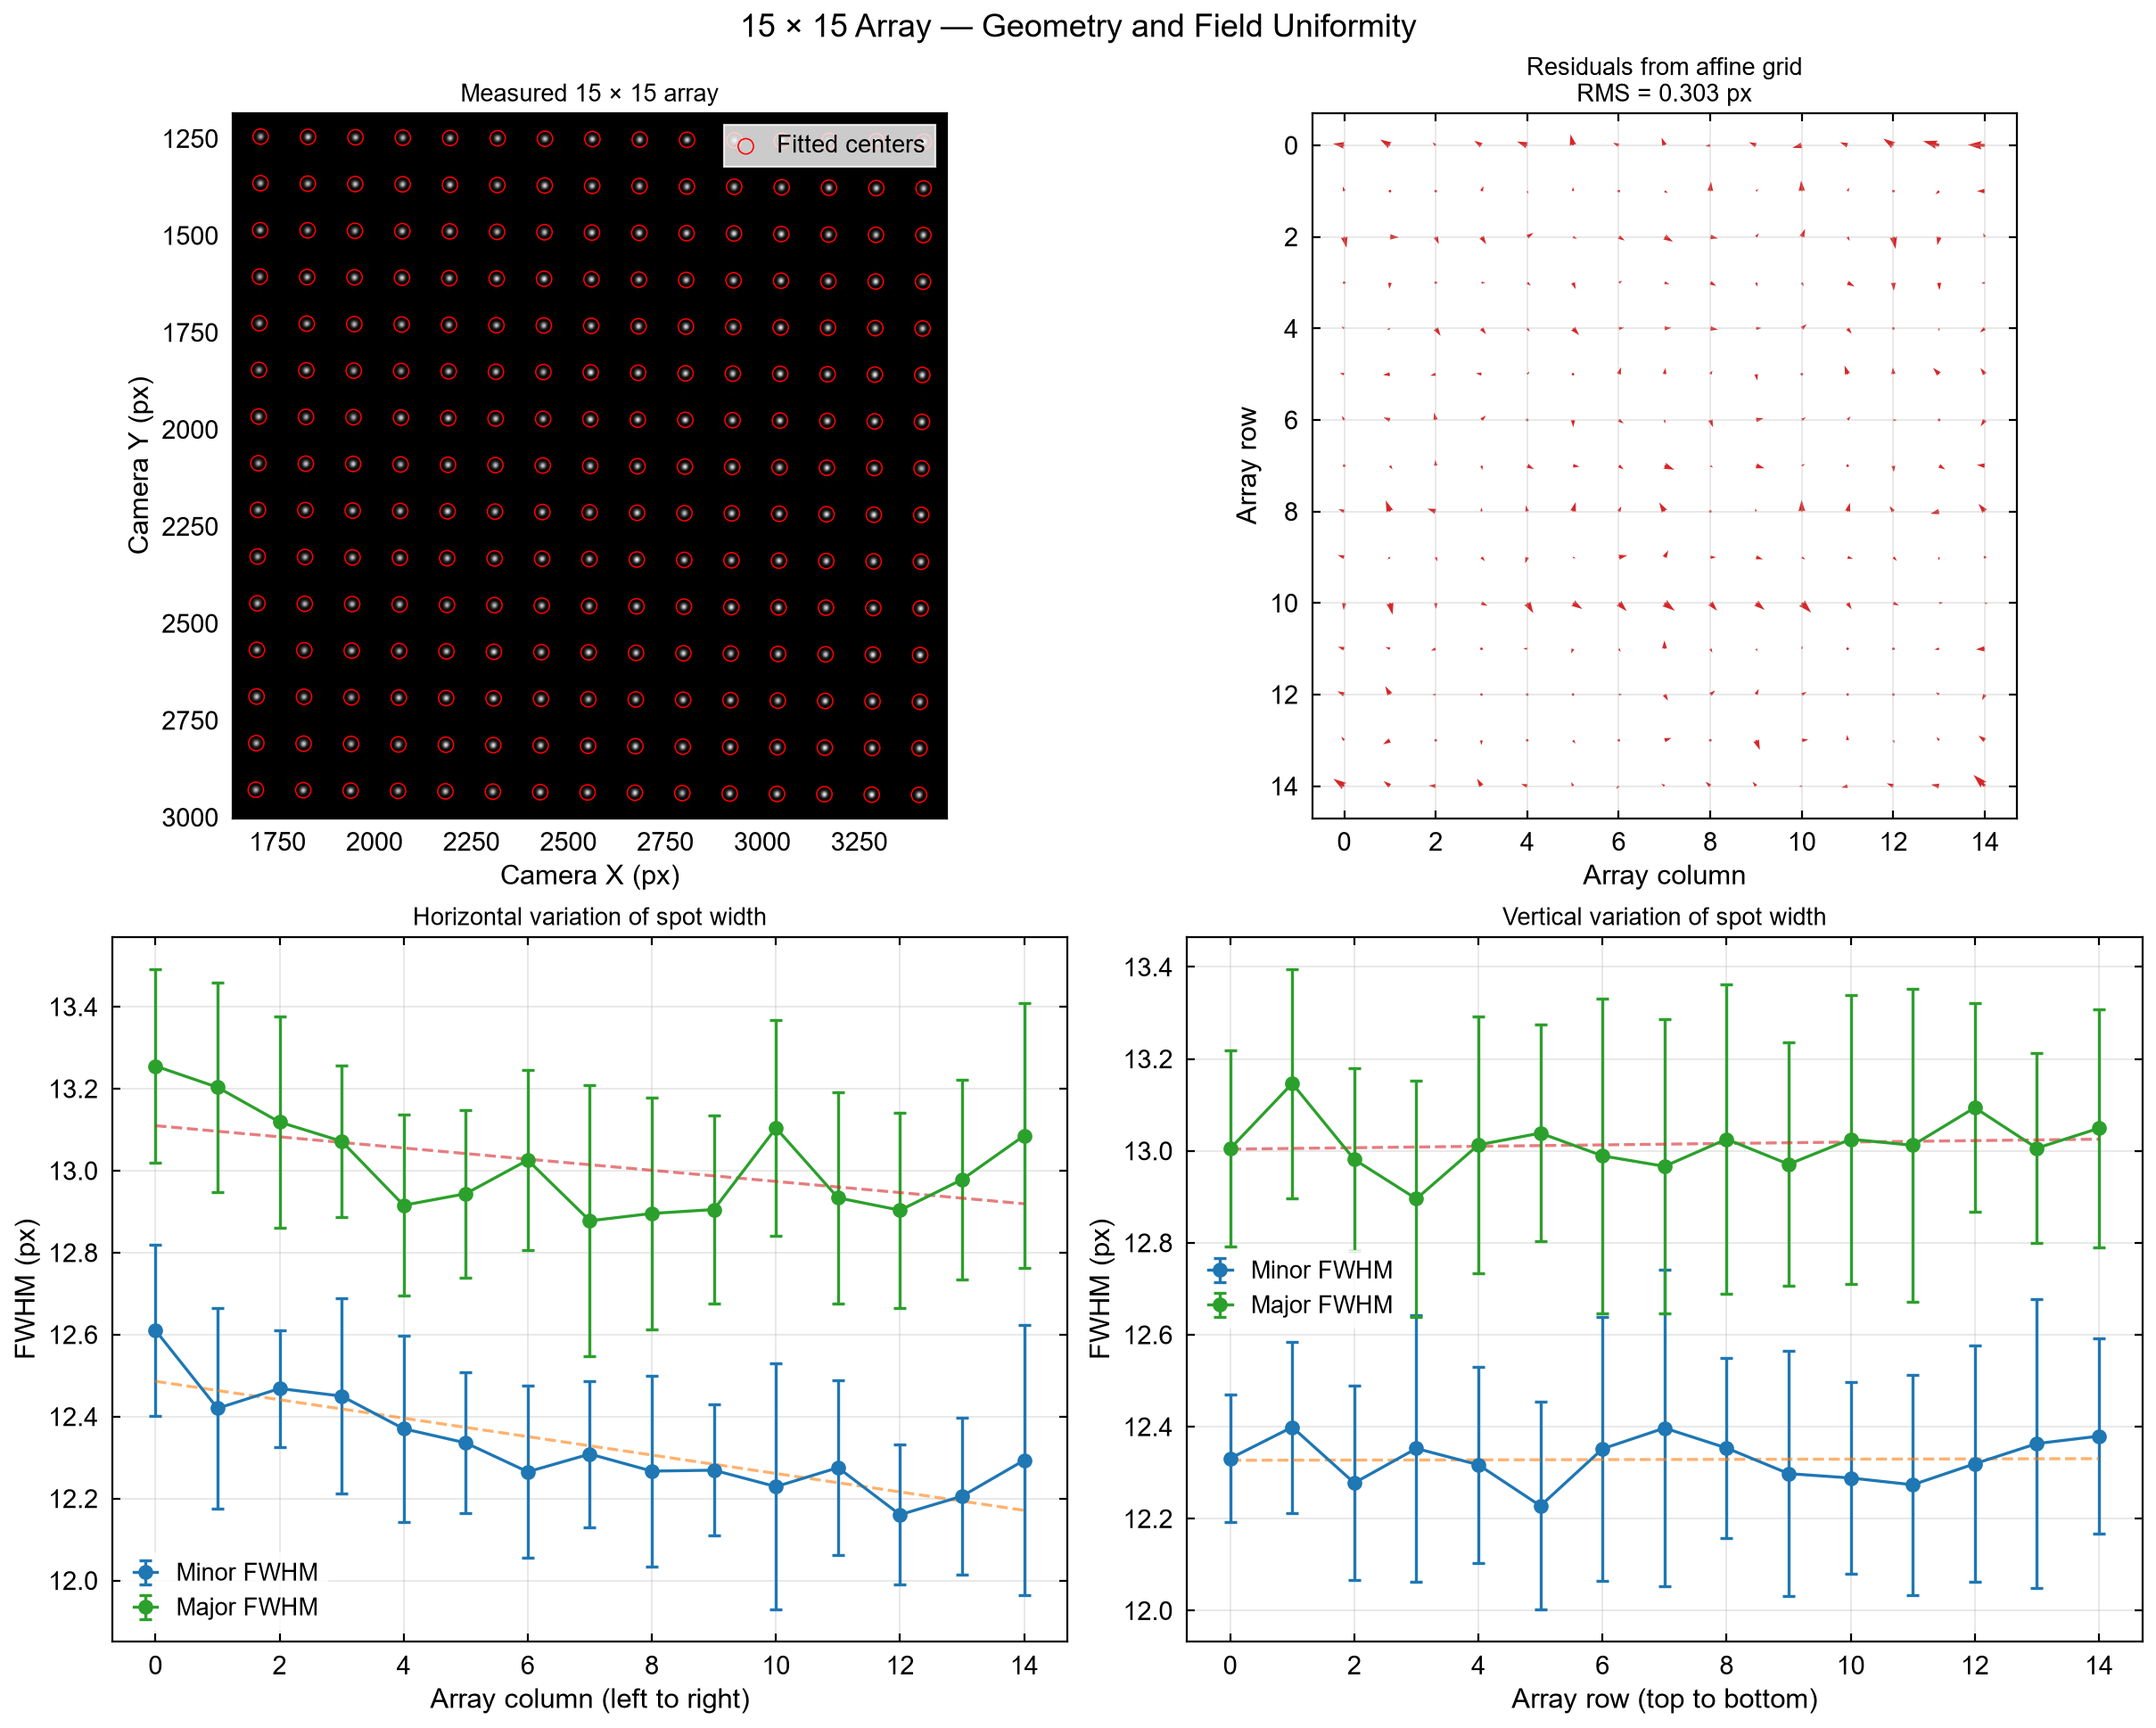

In [24]:

# ============================================================
# 11. GEOMETRY AND SPATIAL TRENDS
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 12),
    constrained_layout=True
)

# ------------------------------------------------------------
# A. Measured image with fitted spot positions
# ------------------------------------------------------------

ax = axes[0, 0]

ax.imshow(
    image,
    cmap="gray",
    vmin=0,
    vmax=np.percentile(df["peak_measured"], 99)
)

ax.scatter(
    df["x_px"],
    df["y_px"],
    s=60,
    facecolors="none",
    edgecolors="red",
    linewidths=0.7,
    label="Fitted centers"
)

ax.set_xlim(
    df["x_px"].min()-60,
    df["x_px"].max()+60
)

ax.set_ylim(
    df["y_px"].max()+60,
    df["y_px"].min()-60
)

ax.set_xlabel("Camera X (px)")
ax.set_ylabel("Camera Y (px)")

ax.set_title("Measured 15 × 15 array")
ax.legend()


# ------------------------------------------------------------
# B. Position residuals
# ------------------------------------------------------------

ax = axes[0, 1]

ax.quiver(
    df["col"],
    df["row"],
    df["residual_x_px"],
    df["residual_y_px"],
    angles="xy",
    scale_units="xy",
    scale=2,
    color="tab:red"
)

ax.set_aspect("equal")
ax.invert_yaxis()

ax.set_xlabel("Array column")
ax.set_ylabel("Array row")

ax.set_title(
    "Residuals from affine grid\n"
    f"RMS = {rms_position_error:.3f} px"
)

ax.grid(alpha=0.3)


# ------------------------------------------------------------
# C. FWHM variation across X
# ------------------------------------------------------------

ax = axes[1, 0]

group_x = df.groupby("col")

x_index = np.arange(NX)

for column, label in [
    ("fwhm_minor_px", "Minor FWHM"),
    ("fwhm_major_px", "Major FWHM")
]:

    mean_values = group_x[column].mean().to_numpy()
    std_values = group_x[column].std().to_numpy()

    ax.errorbar(
        x_index,
        mean_values,
        yerr=std_values,
        fmt="o-",
        capsize=3,
        label=label
    )

    # Linear trend
    trend = np.polyfit(
        x_index,
        mean_values,
        1
    )

    ax.plot(
        x_index,
        np.polyval(trend, x_index),
        "--",
        alpha=0.6
    )

    print(
        f"X gradient, {label}: "
        f"{trend[0]*(NX-1):+.4f} px "
        f"across array"
    )

ax.set_xlabel("Array column (left to right)")
ax.set_ylabel("FWHM (px)")
ax.set_title("Horizontal variation of spot width")
ax.legend()
ax.grid(alpha=0.3)


# ------------------------------------------------------------
# D. FWHM variation across Y
# ------------------------------------------------------------

ax = axes[1, 1]

group_y = df.groupby("row")

y_index = np.arange(NY)

for column, label in [
    ("fwhm_minor_px", "Minor FWHM"),
    ("fwhm_major_px", "Major FWHM")
]:

    mean_values = group_y[column].mean().to_numpy()
    std_values = group_y[column].std().to_numpy()

    ax.errorbar(
        y_index,
        mean_values,
        yerr=std_values,
        fmt="o-",
        capsize=3,
        label=label
    )

    trend = np.polyfit(
        y_index,
        mean_values,
        1
    )

    ax.plot(
        y_index,
        np.polyval(trend, y_index),
        "--",
        alpha=0.6
    )

    print(
        f"Y gradient, {label}: "
        f"{trend[0]*(NY-1):+.4f} px "
        f"across array"
    )

ax.set_xlabel("Array row (top to bottom)")
ax.set_ylabel("FWHM (px)")
ax.set_title("Vertical variation of spot width")
ax.legend()
ax.grid(alpha=0.3)

fig.suptitle(
    "15 × 15 Array — Geometry and Field Uniformity",
    fontsize=16
)

plt.savefig(
    "SLM_15x15_geometry_and_focus.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


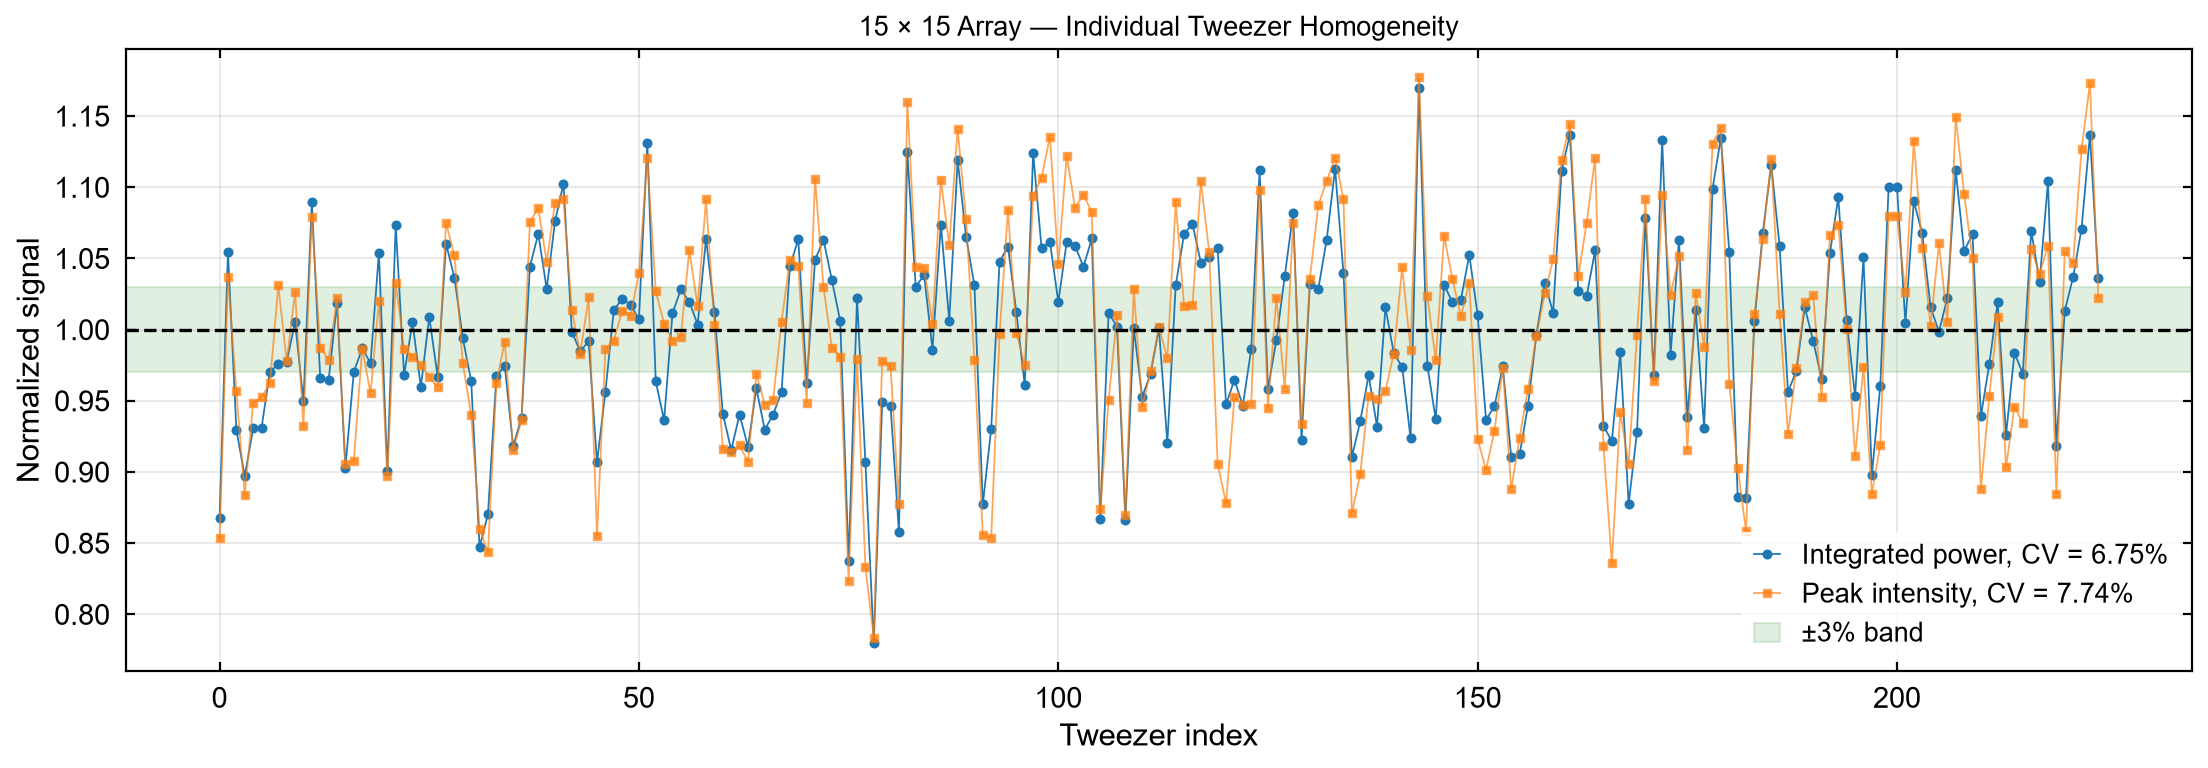

In [25]:

# ============================================================
# 12. INDIVIDUAL TWEEZER POWERS
# ============================================================

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df["power_normalized"],
    "o-",
    markersize=3,
    linewidth=0.8,
    label=f"Integrated power, CV = {CV(power):.2f}%"
)

ax.plot(
    df["peak_normalized"],
    "s-",
    markersize=3,
    linewidth=0.8,
    alpha=0.7,
    label=f"Peak intensity, CV = {CV(peak):.2f}%"
)

ax.axhline(
    1.0,
    color="black",
    linestyle="--"
)

ax.axhspan(
    0.97,
    1.03,
    color="green",
    alpha=0.12,
    label="±3% band"
)

ax.set_xlabel("Tweezer index")
ax.set_ylabel("Normalized signal")

ax.set_title(
    "15 × 15 Array — Individual Tweezer Homogeneity"
)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "SLM_15x15_normalized_powers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
